# Bitcoin forecasting with PatchTST - Standalone
Chronological Train 80% / Test 20%; no validation, tuning or early stopping. Five predefined seeds, one fixed 100-epoch training run per seed. Frozen weights and BatchNorm statistics during rolling-origin forecasting. Price-derived returns only; USD RMSE and MAPE (%); horizons are calendar days.

Use kernel **Python 3.12 (vs_nine TensorFlow)**, which includes CPU PyTorch. Outputs: `PROJECT_2026/OUTPUT/outputs_patchtst/{tables,figures,models,summaries}`. Historical Test forecasts and forecasts beyond the last observation are displayed separately. This notebook runs independently of other model notebooks.

## Step 1 - Environment setup and fixed configuration
CPU is the default. Seed Python, NumPy and PyTorch; enable deterministic algorithms. Model/training configuration is checked against the official ETTh1 script and parser. BTC task settings such as 60-day lookback and 30-day output remain the user's explicit data design.

The reference experiment has a different lookback, targets, data frequency and seed. It is a source for model settings, not permission to alter this BTC experiment or introduce validation. See the generated `hyperparameter_sources.md`.

In [1]:
from pathlib import Path
import sys
import json
import warnings
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import hashlib
import time
import random
import sklearn
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import Adam
from torch.optim.lr_scheduler import OneCycleLR
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
import scipy
from scipy import stats
from IPython.display import display, Markdown, HTML

DATA_PATH = 'Bitcoin_Historical_Data.csv'
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
MAX_H = 30
DAILY_FORECAST_WINDOWS = [7, 30]
TRAIN_RATIO = 0.8
LOOKBACK = 60
SEEDS = [0, 1, 2, 3, 4]
PATCH_LEN = 16
STRIDE = 8
PADDING_PATCH = 'end'
N_LAYERS = 3
N_HEADS = 4
D_MODEL = 16
D_FF = 128
DROPOUT = 0.3
FC_DROPOUT = 0.3
HEAD_DROPOUT = 0.0
REVIN = True
LR = 1e-4
BATCH_SIZE = 128
EPOCHS = 100
PCT_START = 0.3
DEVICE = torch.device('cpu')

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# One CPU thread avoids oversubscription for this small network.
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
set_seed(SEEDS[0])
ALPHA = 0.05
assert max(HORIZONS) == MAX_H
assert max(DAILY_FORECAST_WINDOWS) <= MAX_H
search_dirs = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((base for base in search_dirs
    if (base/'BTC_TEST').is_dir() and (base/'CSV').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Launch JupyterLab inside PROJECT_2026 or BTC_TEST.')
data_file = Path(DATA_PATH)
if not data_file.is_file():
    paths = [base/rel for base in search_dirs for rel in
        ['Bitcoin_Historical_Data.csv','BTC_TEST/Bitcoin_Historical_Data.csv',
         'CSV/Bitcoin Historical Data.csv','CSV/Bitcoin_Historical_Data.csv']]
    data_file = next((path for path in paths if path.is_file()), data_file)
if not data_file.is_file(): raise FileNotFoundError('Set DATA_PATH to the Bitcoin CSV.')
DATA_PATH = str(data_file.resolve())
OUTPUT_DIR = PROJECT_ROOT/'OUTPUT'/'outputs_patchtst'
TABLE_DIR, FIGURE_DIR, MODEL_DIR = (OUTPUT_DIR/name for name in ['tables','figures','models'])
SUMMARY_DIR = OUTPUT_DIR/'summaries'
for directory in [TABLE_DIR,FIGURE_DIR,MODEL_DIR,SUMMARY_DIR]: directory.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(12,5),'axes.grid':True,'grid.alpha':0.25,'figure.dpi':110})
versions = pd.DataFrame([(name,version(name)) for name in
    ['pandas','numpy','matplotlib','scikit-learn','torch','statsmodels','scipy']],columns=['library','version'])
print('Python:',sys.version,'\nExecutable:',sys.executable)
display(versions)
print('Data:',DATA_PATH,'\nOutputs:',OUTPUT_DIR)
versions.to_csv(TABLE_DIR/'library_versions.csv',index=False)
def save_table(frame,name): frame.to_csv(TABLE_DIR/name,index=False,encoding='utf-8-sig')
def save_figure(fig,name):
    fig.tight_layout(); fig.savefig(FIGURE_DIR/name,dpi=180,bbox_inches='tight')
    plt.show(); plt.close(fig)
def show_scroll_table(frame):
    display(HTML('<div style="max-height:360px;overflow:auto;border:1px solid #ddd;padding:8px">'
        +frame.to_html(index=False,float_format=lambda x:f'{x:,.2f}')+'</div>'))

Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe


,library,version
0,pandas,2.3.3
1,numpy,2.5.3
2,matplotlib,3.11.1
3,scikit-learn,1.9.1
4,torch,2.14.1+cpu
5,statsmodels,0.15.0
6,scipy,1.18.1


Data: C:\Users\User\Desktop\PROJECT_2026\CSV\Bitcoin Historical Data.csv 
Outputs: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\outputs_patchtst


### Configuration provenance - checked before Test evaluation

In [2]:
official_script = 'https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh'
official_parser = 'https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/run_longExp.py'
official_backbone = 'https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/layers/PatchTST_backbone.py'
rows = []
for name, value, argument in [
    ('PATCH_LEN',PATCH_LEN,'patch_len'),('STRIDE',STRIDE,'stride'),
    ('N_LAYERS',N_LAYERS,'e_layers'),('N_HEADS',N_HEADS,'n_heads'),
    ('D_MODEL',D_MODEL,'d_model'),('D_FF',D_FF,'d_ff'),
    ('DROPOUT',DROPOUT,'dropout'),('FC_DROPOUT',FC_DROPOUT,'fc_dropout'),
    ('HEAD_DROPOUT',HEAD_DROPOUT,'head_dropout'),('LR',LR,'learning_rate'),
    ('BATCH_SIZE',BATCH_SIZE,'batch_size'),('EPOCHS',EPOCHS,'train_epochs')]:
    rows.append(dict(setting=name,used=repr(value),reference=repr(value),
        status='MATCH',source=f'{official_script} (--{argument})'))
for name,value,argument,reference in [
    ('PADDING_PATCH',PADDING_PATCH,'padding_patch',"'end'"),
    ('REVIN',REVIN,'revin','1 / True'),('PCT_START',PCT_START,'pct_start','0.3')]:
    rows.append(dict(setting=name,used=repr(value),reference=reference,
        status='MATCH',source=f'{official_parser} (--{argument} default)'))
for name,value,reference,note in [
    ('DATA_PATH',DATA_PATH,'ETTh1.csv','User BTC dataset; resolves actual CSV path'),
    ('HORIZONS',HORIZONS,'96, 192, 336, 720','User daily BTC horizons'),
    ('MAX_H',MAX_H,'96, 192, 336, 720','User 30 daily outputs'),
    ('TRAIN_RATIO',TRAIN_RATIO,'Not a shared ratio in etth1.sh','User chronological 80/20, no validation'),
    ('LOOKBACK',LOOKBACK,'336','User explicit 60-day windows, not ETTh1 hourly context'),
    ('SEEDS',SEEDS,'2021','User five predefined seeds, not selection by Test'),
    ('ALPHA',ALPHA,'Not specified','User diagnostic significance level'),
    ('DEVICE',str(DEVICE),'GPU when available','User CPU default for reproducibility')]:
    rows.append(dict(setting=name,used=repr(value),reference=reference,
        status='TASK SETTING',source=note))
hyperparameter_sources = pd.DataFrame(rows)
save_table(hyperparameter_sources,'hyperparameter_sources.csv')
lines=['# PatchTST hyperparameter sources','',
    'Checked against the official ETTh1 supervised script and parser on 2026-10-03.',
    'Model/training scalar values in the supplied PatchTST block match the reference. No scalar corrections are required.',
    'Task data, horizons, raw split, lookback and seed list are explicit BTC requirements, not copied ETTh1 experiment settings.',
    '', '| Setting | Used | Official / reference | Status | Source |',
    '|---|---|---|---|---|']
for row in hyperparameter_sources.itertuples(index=False):
    lines.append(f'| {row.setting} | {row.used} | {row.reference} | {row.status} | {row.source} |')
lines += ['', '## Architecture and scheduling cautions',
    f'- End padding follows [the official backbone]({official_backbone}): replicate the last value STRIDE times before unfold.',
    '- With the user lookback 60, patch length 16 and stride 8, padded length is 68 and patch count is 7.',
    '- FC_DROPOUT is the official fc_dropout argument. In the supervised flatten head it is not an additional head dropout; HEAD_DROPOUT controls the flatten head dropout.',
    '- The official backbone uses BatchNorm, GELU and residual attention by default; a generic TransformerEncoder is not automatically an equivalent implementation.',
    '- PCT_START=0.3 matches the parser. OneCycleLR is requested by the user, but the ETTh1 script inherits lradj=type3; the scalar match does not imply an identical full scheduling protocol.',
    '- No validation, early stopping or checkpoint selection from the reference experiment will be adopted.',
    '- The completed model uses non-affine RevIN (parser default affine=0), GELU, post-residual BatchNorm and residual attention as in the official supervised backbone. Attention probability dropout=0; projection/residual/feed-forward dropout=DROPOUT. FC_DROPOUT is recorded but does not add a layer to the supervised flatten head. The fixed OneCycleLR protocol follows the explicit user training specification; no validation-dependent schedule is used.']
source_markdown='\n'.join(lines)
(SUMMARY_DIR/'hyperparameter_sources.md').write_text(source_markdown,encoding='utf-8')
display(Markdown(source_markdown))

# PatchTST hyperparameter sources

Checked against the official ETTh1 supervised script and parser on 2026-10-03.
Model/training scalar values in the supplied PatchTST block match the reference. No scalar corrections are required.
Task data, horizons, raw split, lookback and seed list are explicit BTC requirements, not copied ETTh1 experiment settings.

| Setting | Used | Official / reference | Status | Source |
|---|---|---|---|---|
| PATCH_LEN | 16 | 16 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--patch_len) |
| STRIDE | 8 | 8 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--stride) |
| N_LAYERS | 3 | 3 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--e_layers) |
| N_HEADS | 4 | 4 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--n_heads) |
| D_MODEL | 16 | 16 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--d_model) |
| D_FF | 128 | 128 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--d_ff) |
| DROPOUT | 0.3 | 0.3 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--dropout) |
| FC_DROPOUT | 0.3 | 0.3 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--fc_dropout) |
| HEAD_DROPOUT | 0.0 | 0.0 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--head_dropout) |
| LR | 0.0001 | 0.0001 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--learning_rate) |
| BATCH_SIZE | 128 | 128 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--batch_size) |
| EPOCHS | 100 | 100 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh (--train_epochs) |
| PADDING_PATCH | 'end' | 'end' | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/run_longExp.py (--padding_patch default) |
| REVIN | True | 1 / True | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/run_longExp.py (--revin default) |
| PCT_START | 0.3 | 0.3 | MATCH | https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/run_longExp.py (--pct_start default) |
| DATA_PATH | 'C:\\Users\\User\\Desktop\\PROJECT_2026\\CSV\\Bitcoin Historical Data.csv' | ETTh1.csv | TASK SETTING | User BTC dataset; resolves actual CSV path |
| HORIZONS | [1, 3, 5, 7, 14, 21, 30] | 96, 192, 336, 720 | TASK SETTING | User daily BTC horizons |
| MAX_H | 30 | 96, 192, 336, 720 | TASK SETTING | User 30 daily outputs |
| TRAIN_RATIO | 0.8 | Not a shared ratio in etth1.sh | TASK SETTING | User chronological 80/20, no validation |
| LOOKBACK | 60 | 336 | TASK SETTING | User explicit 60-day windows, not ETTh1 hourly context |
| SEEDS | [0, 1, 2, 3, 4] | 2021 | TASK SETTING | User five predefined seeds, not selection by Test |
| ALPHA | 0.05 | Not specified | TASK SETTING | User diagnostic significance level |
| DEVICE | 'cpu' | GPU when available | TASK SETTING | User CPU default for reproducibility |

## Architecture and scheduling cautions
- End padding follows [the official backbone](https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/layers/PatchTST_backbone.py): replicate the last value STRIDE times before unfold.
- With the user lookback 60, patch length 16 and stride 8, padded length is 68 and patch count is 7.
- FC_DROPOUT is the official fc_dropout argument. In the supervised flatten head it is not an additional head dropout; HEAD_DROPOUT controls the flatten head dropout.
- The official backbone uses BatchNorm, GELU and residual attention by default; a generic TransformerEncoder is not automatically an equivalent implementation.
- PCT_START=0.3 matches the parser. OneCycleLR is requested by the user, but the ETTh1 script inherits lradj=type3; the scalar match does not imply an identical full scheduling protocol.
- No validation, early stopping or checkpoint selection from the reference experiment will be adopted.
- The completed model uses non-affine RevIN (parser default affine=0), GELU, post-residual BatchNorm and residual attention as in the official supervised backbone. Attention probability dropout=0; projection/residual/feed-forward dropout=DROPOUT. FC_DROPOUT is recorded but does not add a layer to the supervised flatten head. The fixed OneCycleLR protocol follows the explicit user training specification; no validation-dependent schedule is used.

## Step 2 - Data Preparation
Convert source strings, sort oldest to newest, and establish a daily calendar index without imputing prices.
Keep volume B rows; volume is not a model feature. The first log return is necessarily NaN and is excluded from scaler fitting and all windows.


In [3]:
raw = pd.read_csv(DATA_PATH, dtype=str)
required = ['Date','Price','Open','High','Low','Vol.','Change %']
assert set(required).issubset(raw.columns)
assert not raw[required].isna().any().any()
df = raw[required].copy()
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='raise')
assert not df['Date'].duplicated().any(), 'Duplicate dates'
df = df.sort_values('Date')
for column in ['Price','Open','High','Low']:
    df[column] = pd.to_numeric(df[column].str.replace(',', '', regex=False), errors='raise').astype(float)
vol = df['Vol.'].str.strip().str.upper().str.replace(',', '', regex=False)
parts = vol.str.extract(r'^(?P<number>\d+(?:\.\d+)?)(?P<suffix>[KMB]?)$')
assert parts.notna().all().all(), 'Unknown volume format'
df['Volume'] = pd.to_numeric(parts['number']) * parts['suffix'].map({'':1.,'K':1e3,'M':1e6,'B':1e9})
b_rows = df.loc[vol.str.endswith('B')].copy()
save_table(b_rows, 'volume_B_rows.csv')
print('Volume B rows retained:', len(b_rows))
df['Change %'] = pd.to_numeric(df['Change %'].str.replace('%','',regex=False), errors='raise') / 100
df = df.drop(columns='Vol.').set_index('Date').asfreq('D')
assert df.index.is_monotonic_increasing and df.index.is_unique
assert not df.isna().any().any(), 'Missing data or calendar gaps'
assert np.isfinite(df.to_numpy()).all() and (df['Price'] > 0).all()
assert len(df) == 1897
assert df.index[0] == pd.Timestamp('2021-07-01') and df.index[-1] == pd.Timestamp('2026-09-09')
log_price = np.log(df['Price']).rename('log_price')
log_ret = log_price.diff().rename('log_ret')
assert pd.isna(log_ret.iloc[0]) and log_ret.iloc[1:].notna().all()
display(df.head())


Volume B rows retained: 16


,Price,Open,High,Low,Change %,Volume
Date,,,,,,
2021-07-01,33543.6,35030.7,35032.7,32839.2,-0.0423,27410.0
2021-07-02,33813.4,33542.2,33925.9,32734.6,0.0080,78930.0
2021-07-03,34742.8,33814.2,34909.8,33363.3,0.0275,55690.0
2021-07-04,35298.2,34742.8,35957.6,34740.1,0.0160,56130.0
2021-07-05,33687.8,35297.0,35300.5,33164.1,-0.0456,88360.0


## Step 3 - EDA (Descriptive Only; No Model Decisions)


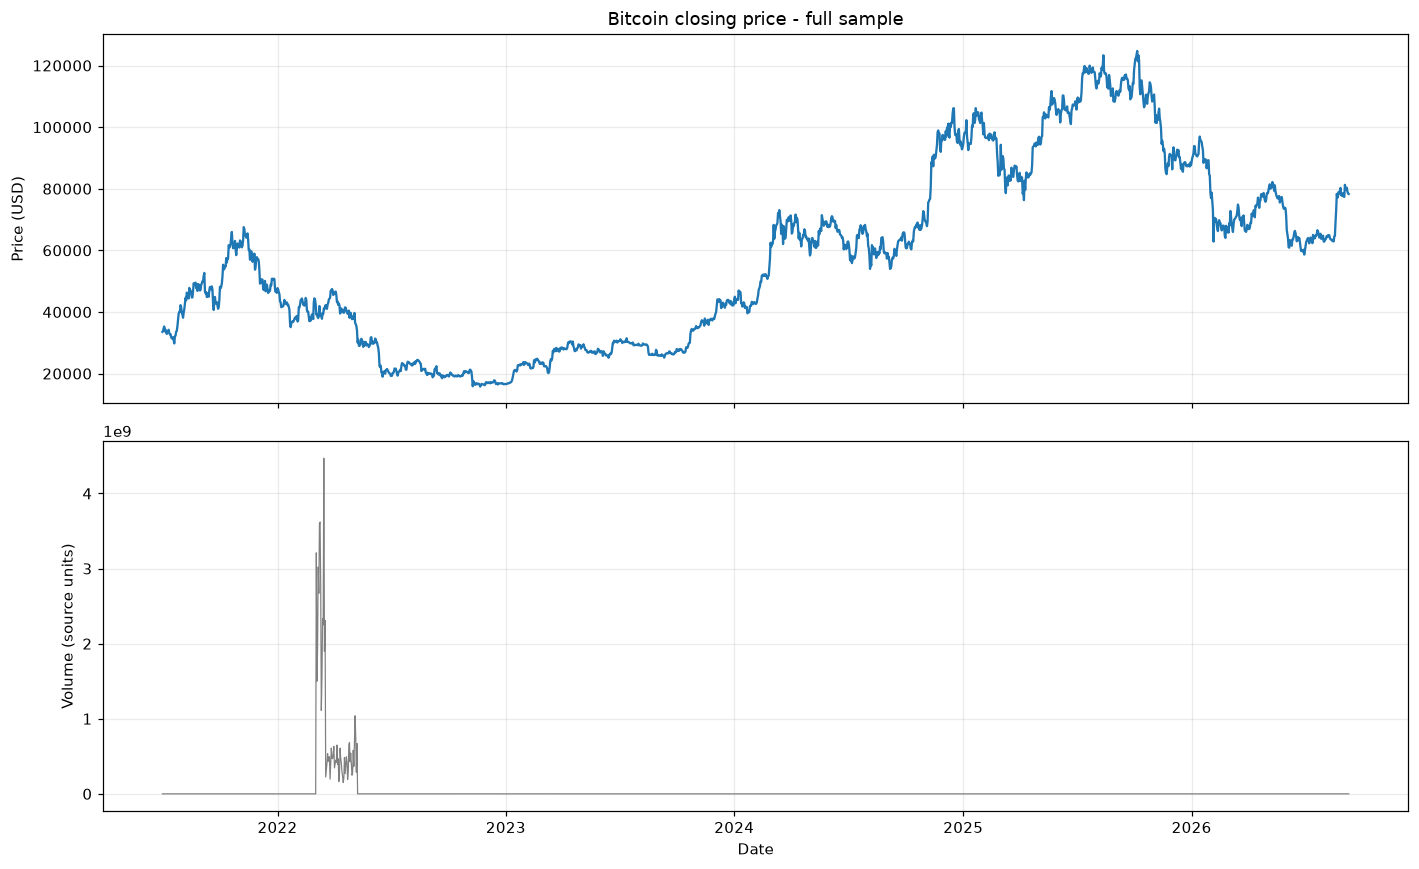

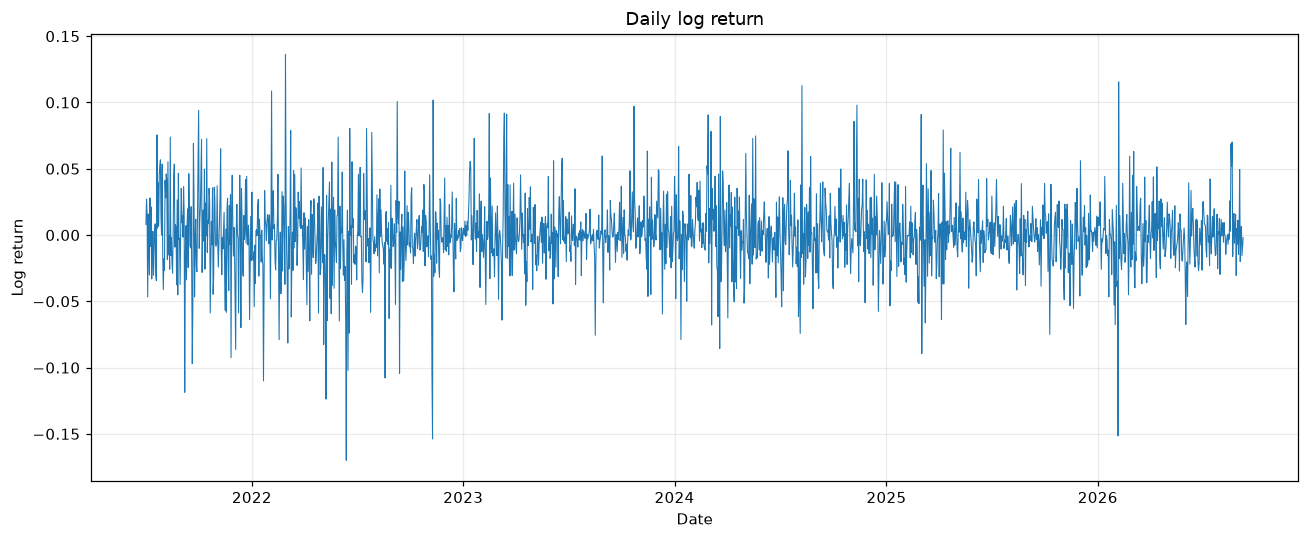

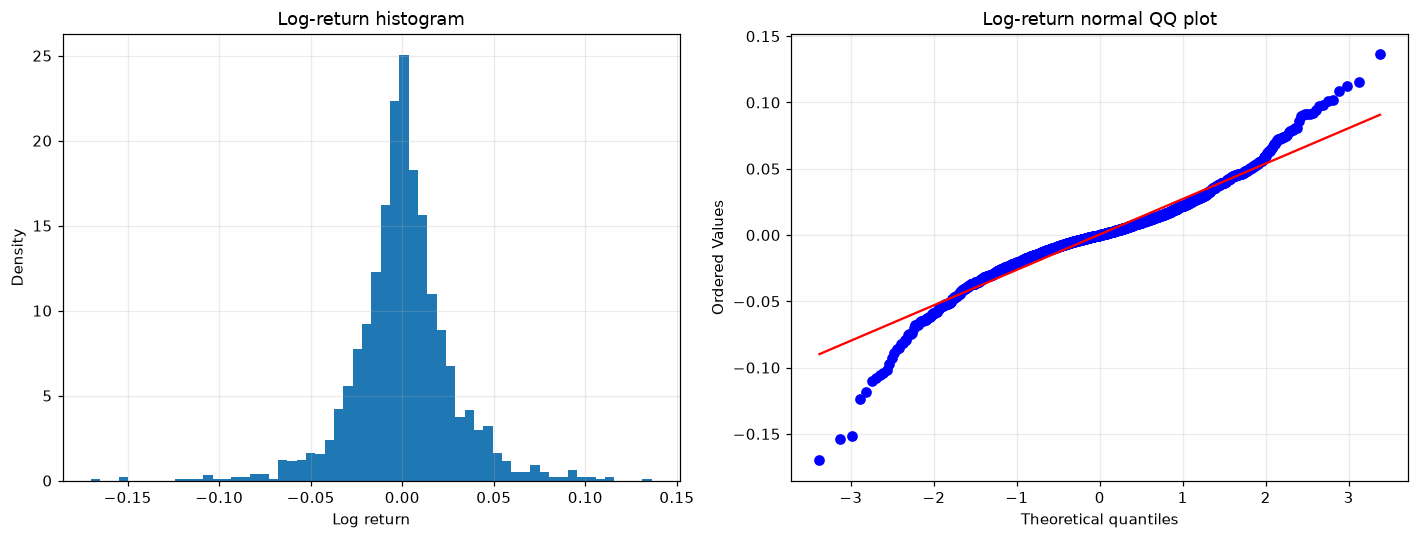

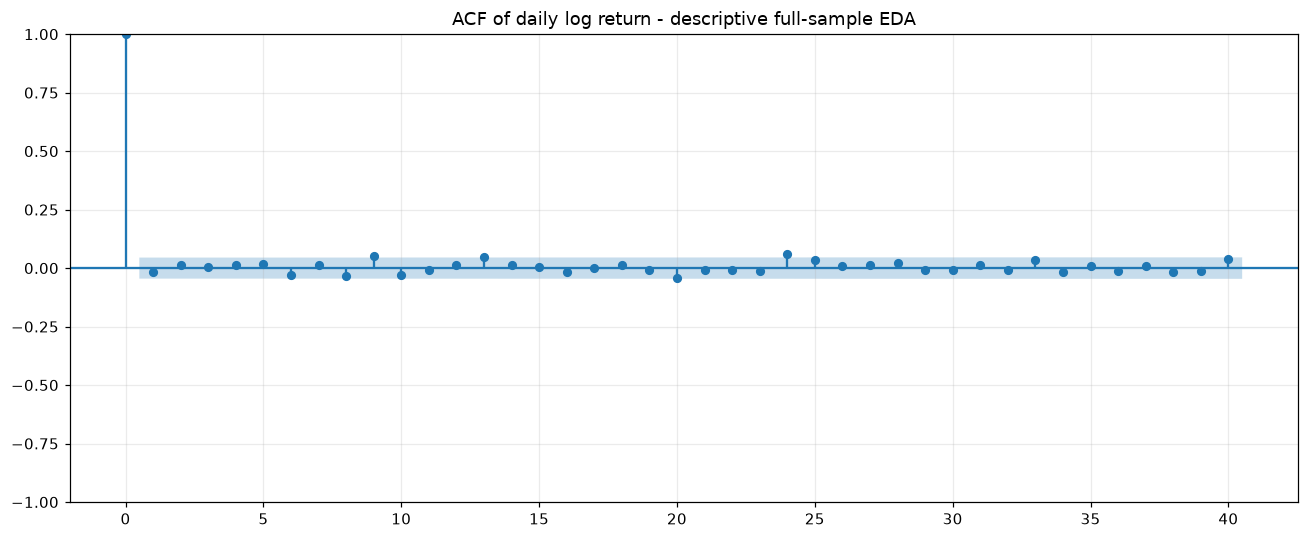

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df.index, df['Price'])
axes[0].set(title='Bitcoin closing price - full sample', ylabel='Price (USD)')
axes[1].plot(df.index, df['Volume'], color='gray', linewidth=0.8)
axes[1].set(ylabel='Volume (source units)', xlabel='Date')
save_figure(fig, '01_raw_price_volume.png')
fig, ax = plt.subplots()
ax.plot(log_ret, linewidth=0.7)
ax.set(title='Daily log return', ylabel='Log return', xlabel='Date')
save_figure(fig, '02_log_return.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(log_ret.dropna(), bins=60, density=True)
axes[0].set(title='Log-return histogram', xlabel='Log return', ylabel='Density')
stats.probplot(log_ret.dropna(), dist='norm', plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig, '03_return_distribution.png')
fig, ax = plt.subplots()
plot_acf(log_ret.dropna(), lags=40, ax=ax)
ax.set_title('ACF of daily log return - descriptive full-sample EDA')
save_figure(fig, '04_acf_log_return.png')


### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [ ]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'USD'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,USD,USD,USD
Start,2021-07-01,2021-07-01,2025-08-26
End,2026-09-09,2025-08-25,2026-09-09
Count,1897,1517,380
Mean,57629.849499,51303.65056,82884.701579
SD,29376.877181,28293.431673,17763.14492
Min,15776.2,15776.2,58630.8
Q1,29798.5,27603.3,67206.375
Median,57534.6,43188.2,78230.25
Q3,78333.9,66798.7,92535.0


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-08-26
End,2026-09-09,2025-08-25,2026-09-09
Count,1896,1516,380
Mean,0.000447,0.000784,-0.000897
SD,0.027453,0.028476,0.022908
Min,-0.169947,-0.169947,-0.151458
Q1,-0.01253,-0.012301,-0.014073
Median,-0.000094,-0.000025,-0.000511
Q3,0.013332,0.014076,0.011167


## Step 4 - Chronological Split BEFORE Scaling and Windowing


,split,start_date,end_date,n_days,price_min,price_max,price_mean,log_ret_n,log_ret_mean,log_ret_std
0,Train,2021-07-01,2025-08-25,1517,15776.2,123323.4,51303.650560,1516,0.000784,0.028476
1,Test,2025-08-26,2026-09-09,380,58630.8,124725.1,82884.701579,380,-0.000897,0.022908


Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).


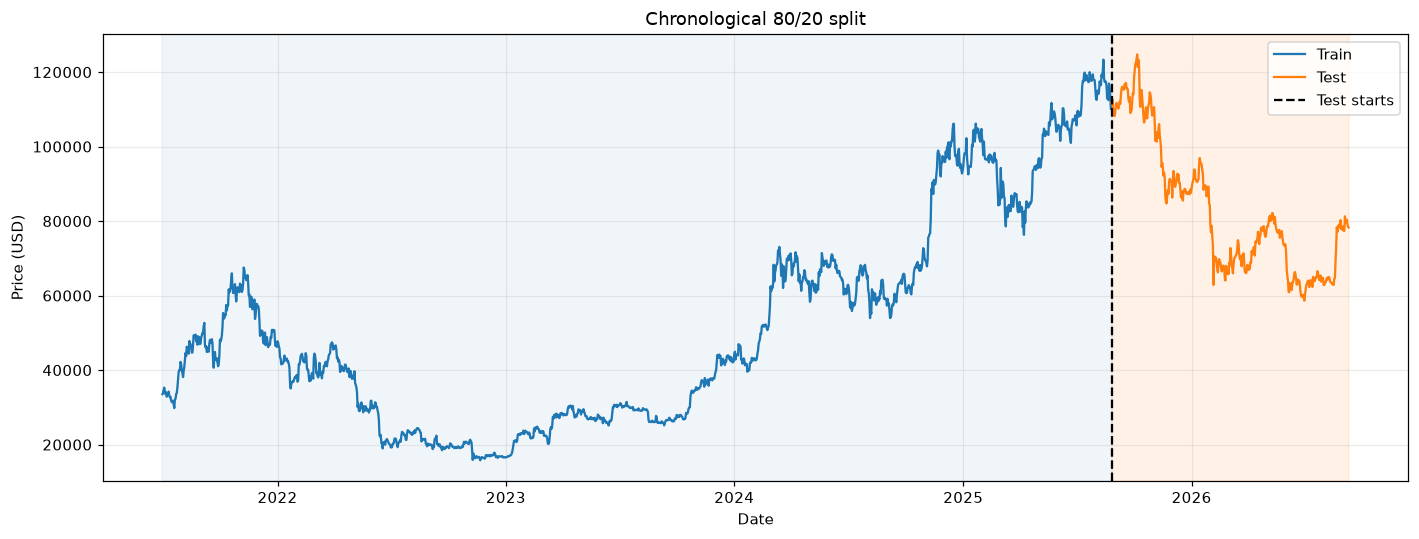

In [5]:
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
TRAIN_END_IDX = n_train - 1
assert (n_train, n_test, TRAIN_END_IDX) == (1517, 380, 1516)
assert df.index[TRAIN_END_IDX] == pd.Timestamp('2025-08-25')
assert df.index[n_train] == pd.Timestamp('2025-08-26')
train_ret = log_ret.iloc[1:n_train].copy()
split_rows = []
for name, start, end in [('Train', 0, n_train), ('Test', n_train, n)]:
    prices = df['Price'].iloc[start:end]
    returns = log_ret.iloc[start:end].dropna()
    split_rows.append(dict(split=name, start_date=prices.index[0], end_date=prices.index[-1],
        n_days=len(prices), price_min=prices.min(), price_max=prices.max(), price_mean=prices.mean(),
        log_ret_n=len(returns), log_ret_mean=returns.mean(), log_ret_std=returns.std(ddof=1)))
split_summary = pd.DataFrame(split_rows)
save_table(split_summary, 'split_summary.csv')
display(split_summary)
print('Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['Price'].iloc[:n_train], label='Train', color='tab:blue')
ax.plot(df['Price'].iloc[n_train:], label='Test', color='tab:orange')
ax.axvspan(df.index[0], df.index[n_train], alpha=0.07, color='tab:blue')
ax.axvspan(df.index[n_train], df.index[-1], alpha=0.10, color='tab:orange')
ax.axvline(df.index[n_train], color='black', linestyle='--', label='Test starts')
ax.set(title='Chronological 80/20 split', ylabel='Price (USD)', xlabel='Date')
ax.legend()
save_figure(fig, '05_train_test_split.png')


## Step 5 - Scaling (Fit on Train Only)
Fit the scaler on return indices 1..1516 only. Transforming later observations with that frozen scaler is permitted for inference; it does not estimate anything from test.
No test values enter the scaler fit or the training windows below.


In [6]:
scaler_fit_indices = np.arange(1, n_train)
assert scaler_fit_indices.max() <= TRAIN_END_IDX
scaler = StandardScaler()
scaler.fit(train_ret.to_numpy().reshape(-1, 1))
assert int(scaler.n_samples_seen_) == len(scaler_fit_indices)
assert train_ret.index.max() <= df.index[TRAIN_END_IDX]
scaler_mean = float(scaler.mean_[0])
scaler_std = float(scaler.scale_[0])
assert scaler_std > 0
np.testing.assert_allclose(scaler_mean, train_ret.mean(), atol=1e-12)
np.testing.assert_allclose(scaler_std, train_ret.std(ddof=0), atol=1e-12)
z = np.full(n, np.nan, dtype=np.float64)
z[1:] = scaler.transform(log_ret.iloc[1:].to_numpy().reshape(-1, 1)).ravel()
assert np.isnan(z[0]) and np.isfinite(z[1:]).all()
scaler_params = dict(mean=scaler_mean, std=scaler_std, ddof=0,
    fit_first_index=int(scaler_fit_indices.min()), fit_last_index=int(scaler_fit_indices.max()),
    n_samples=int(scaler.n_samples_seen_), fit_end_date=str(train_ret.index[-1].date()))
(MODEL_DIR / 'scaler_params.json').write_text(json.dumps(scaler_params, indent=2), encoding='utf-8')
print('Frozen scaler:', scaler_params)


Frozen scaler: {'mean': 0.0007841095418230332, 'std': 0.02846616907695721, 'ddof': 0, 'fit_first_index': 1, 'fit_last_index': 1516, 'n_samples': 1516, 'fit_end_date': '2025-08-25'}


## Step 6 - MIMO Training Windows
X contains 60 scaled returns ending at origin t. y contains the next 30 scaled returns.
Every input and every target lies in train; no validation windows are created.


In [7]:
train_origins = np.arange(LOOKBACK, TRAIN_END_IDX - MAX_H + 1)
train_input_indices = train_origins[:, None] - np.arange(LOOKBACK-1, -1, -1)[None, :]
train_target_indices = train_origins[:, None] + np.arange(1, MAX_H+1)[None, :]
assert train_input_indices.min() >= 1
assert train_input_indices.max() <= TRAIN_END_IDX
assert train_target_indices.max() <= TRAIN_END_IDX
assert (train_input_indices < n_train).all() and (train_target_indices < n_train).all()
X_train = z[train_input_indices][..., None].astype(np.float32)
y_train = z[train_target_indices].astype(np.float32)
assert X_train.shape == (len(train_origins), LOOKBACK, 1)
assert y_train.shape == (len(train_origins), MAX_H)
assert len(train_origins) == TRAIN_END_IDX - MAX_H - LOOKBACK + 1 == 1427
assert np.isfinite(X_train).all() and np.isfinite(y_train).all()
window_audit = pd.DataFrame(dict(origin_idx=train_origins, origin_date=df.index[train_origins],
    input_start_idx=train_input_indices[:, 0], input_end_idx=train_input_indices[:, -1],
    target_start_idx=train_target_indices[:, 0], target_end_idx=train_target_indices[:, -1]))
save_table(window_audit, 'training_window_audit.csv')
print('Training samples:', len(train_origins), 'X:', X_train.shape, 'y:', y_train.shape)
display(window_audit.iloc[[0,-1]])


Training samples: 1427 X: (1427, 60, 1) y: (1427, 30)


,origin_idx,origin_date,input_start_idx,input_end_idx,target_start_idx,target_end_idx
0,60,2021-08-30,1,60,61,90
1426,1486,2025-07-26,1427,1486,1487,1516


### Step 6.1 - Verify patch geometry before model construction
This checks only replication padding and patch shapes. It does not define or train the encoder. The input remains chronological within each window.

In [8]:
assert PADDING_PATCH == 'end'
patch_count = (LOOKBACK+STRIDE-PATCH_LEN)//STRIDE+1
probe = torch.from_numpy(X_train[:2]).transpose(1,2)
padded = nn.ReplicationPad1d((0,STRIDE))(probe)
patches = padded.unfold(dimension=-1,size=PATCH_LEN,step=STRIDE)
assert padded.shape == (2,1,LOOKBACK+STRIDE)
assert patches.shape == (2,1,patch_count,PATCH_LEN)
assert patch_count == 7
assert torch.equal(padded[:,:,-STRIDE:],probe[:,:,-1:].expand(-1,-1,STRIDE))
print('CPU:',DEVICE,'; padded input:',tuple(padded.shape),'; patches:',tuple(patches.shape))
print('Preparation complete. Patch geometry verified before model training.')

CPU: cpu ; padded input: (2, 1, 68) ; patches: (2, 1, 7, 16)
Preparation complete. Patch geometry verified before model training.


## Step 7 - PatchTST architecture, implemented in PyTorch
Univariate channel-independent patch encoder: non-affine RevIN -> end replication padding -> 7 x 16 patches -> linear embedding + learned positions -> three encoder blocks with four-head attention, BatchNorm and GELU -> flatten -> linear 30-day head -> RevIN denormalize.

The encoder accumulates attention logits across blocks (residual attention), following the official backbone. BatchNorm has train-only running statistics and is frozen in eval mode. RevIN uses only the current input window's detached mean/std; it never computes statistics from future targets. `FC_DROPOUT` is a recorded official argument for the pretraining head and is not an extra dropout in the supervised flatten head. `HEAD_DROPOUT=0` makes the specified head ordering equivalent to the official supervised head.

In [9]:
class PatchEncoderBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.heads = N_HEADS
        self.head_dim = D_MODEL//N_HEADS
        self.qkv = nn.Linear(D_MODEL,3*D_MODEL)
        self.project = nn.Sequential(nn.Linear(D_MODEL,D_MODEL),nn.Dropout(DROPOUT))
        self.attention_residual = nn.Dropout(DROPOUT)
        self.bn_attention = nn.BatchNorm1d(D_MODEL)
        self.ff = nn.Sequential(nn.Linear(D_MODEL,D_FF),nn.GELU(),
            nn.Dropout(DROPOUT),nn.Linear(D_FF,D_MODEL))
        self.ff_residual = nn.Dropout(DROPOUT)
        self.bn_ff = nn.BatchNorm1d(D_MODEL)

    def forward(self,x,previous_scores=None):
        batch,patches,_ = x.shape
        q,k,v = self.qkv(x).chunk(3,dim=-1)
        def heads(t): return t.reshape(batch,patches,self.heads,self.head_dim).transpose(1,2)
        q,k,v = heads(q),heads(k),heads(v)
        scores = (q@k.transpose(-1,-2)) * (self.head_dim**-0.5)
        if previous_scores is not None: scores = scores+previous_scores
        attended = (scores.softmax(dim=-1)@v).transpose(1,2).reshape(batch,patches,D_MODEL)
        x = self.bn_attention((x+self.attention_residual(self.project(attended))).transpose(1,2)).transpose(1,2)
        x = self.bn_ff((x+self.ff_residual(self.ff(x))).transpose(1,2)).transpose(1,2)
        return x,scores

class PatchTST(nn.Module):
    def __init__(self):
        super().__init__()
        assert D_MODEL%N_HEADS==0 and PADDING_PATCH=='end'
        self.patch_count = (LOOKBACK+STRIDE-PATCH_LEN)//STRIDE+1
        self.pad = nn.ReplicationPad1d((0,STRIDE))
        self.embedding = nn.Linear(PATCH_LEN,D_MODEL)
        self.position = nn.Parameter(torch.empty(self.patch_count,D_MODEL))
        nn.init.uniform_(self.position,-0.02,0.02)
        self.embedding_dropout = nn.Dropout(DROPOUT)
        self.encoder = nn.ModuleList([PatchEncoderBlock() for _ in range(N_LAYERS)])
        self.head = nn.Sequential(nn.Flatten(start_dim=1),nn.Dropout(HEAD_DROPOUT),
            nn.Linear(self.patch_count*D_MODEL,MAX_H))

    def forward(self,x):
        assert x.ndim==3 and x.shape[1:]==(LOOKBACK,1)
        mean = x.mean(dim=1,keepdim=True).detach()
        std = torch.sqrt(x.var(dim=1,keepdim=True,unbiased=False)+1e-5).detach()
        normalized = (x-mean)/std if REVIN else x
        patches = self.pad(normalized.transpose(1,2)).unfold(-1,PATCH_LEN,STRIDE).squeeze(1)
        assert patches.shape[1:]==(self.patch_count,PATCH_LEN)
        encoded = self.embedding_dropout(self.embedding(patches)+self.position)
        scores = None
        for block in self.encoder: encoded,scores = block(encoded,scores)
        # Official flattened representation is feature-major: (D_MODEL, patches).
        predicted = self.head(encoded.transpose(1,2))
        if REVIN: predicted = predicted*std[:,0,:]+mean[:,0,:]
        return predicted

def weights_digest(model):
    digest=hashlib.sha256()
    for name,value in sorted(model.state_dict().items()):
        array=value.detach().cpu().contiguous().numpy()
        digest.update(name.encode()); digest.update(str(array.dtype).encode())
        digest.update(str(array.shape).encode()); digest.update(array.tobytes())
    return digest.hexdigest()

set_seed(SEEDS[0])
architecture_model=PatchTST().to(DEVICE)
parameter_count=sum(p.numel() for p in architecture_model.parameters())
architecture_model.eval()
with torch.no_grad():
    output_probe=architecture_model(torch.from_numpy(X_train[:2]).to(DEVICE))
assert output_probe.shape==(2,MAX_H) and torch.isfinite(output_probe).all()
architecture_text=str(architecture_model)+f'\nTotal trainable parameters: {parameter_count}\nTraining samples: {len(X_train)}\n'
print(architecture_text)
(MODEL_DIR/'model_architecture.txt').write_text(architecture_text,encoding='utf-8')
del architecture_model

PatchTST(
  (pad): ReplicationPad1d((0, 8))
  (embedding): Linear(in_features=16, out_features=16, bias=True)
  (embedding_dropout): Dropout(p=0.3, inplace=False)
  (encoder): ModuleList(
    (0-2): 3 x PatchEncoderBlock(
      (qkv): Linear(in_features=16, out_features=48, bias=True)
      (project): Sequential(
        (0): Linear(in_features=16, out_features=16, bias=True)
        (1): Dropout(p=0.3, inplace=False)
      )
      (attention_residual): Dropout(p=0.3, inplace=False)
      (bn_attention): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (ff): Sequential(
        (0): Linear(in_features=16, out_features=128, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.3, inplace=False)
        (3): Linear(in_features=128, out_features=16, bias=True)
      )
      (ff_residual): Dropout(p=0.3, inplace=False)
      (bn_ff): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)

## Step 8 - Fixed-budget training once per predefined seed
Adam with MSE, 100 epochs, fixed OneCycleLR schedule; only training loss is calculated. DataLoader shuffles complete training samples with a seeded generator; temporal order inside each window is preserved. Final-epoch weights are saved for every seed without selecting a checkpoint or seed by Test performance.

Training seed=0: 100 fixed epochs


  seed=0 epoch=20: Train MSE=1.263651


  seed=0 epoch=40: Train MSE=1.123092


  seed=0 epoch=60: Train MSE=1.054719


  seed=0 epoch=80: Train MSE=1.037150


...

  seed=4 epoch=40: Train MSE=1.115770


  seed=4 epoch=60: Train MSE=1.051273


  seed=4 epoch=80: Train MSE=1.038882


  seed=4 epoch=100: Train MSE=1.037782


Saved seed=4; Train MSE 1.338294 -> 1.037782


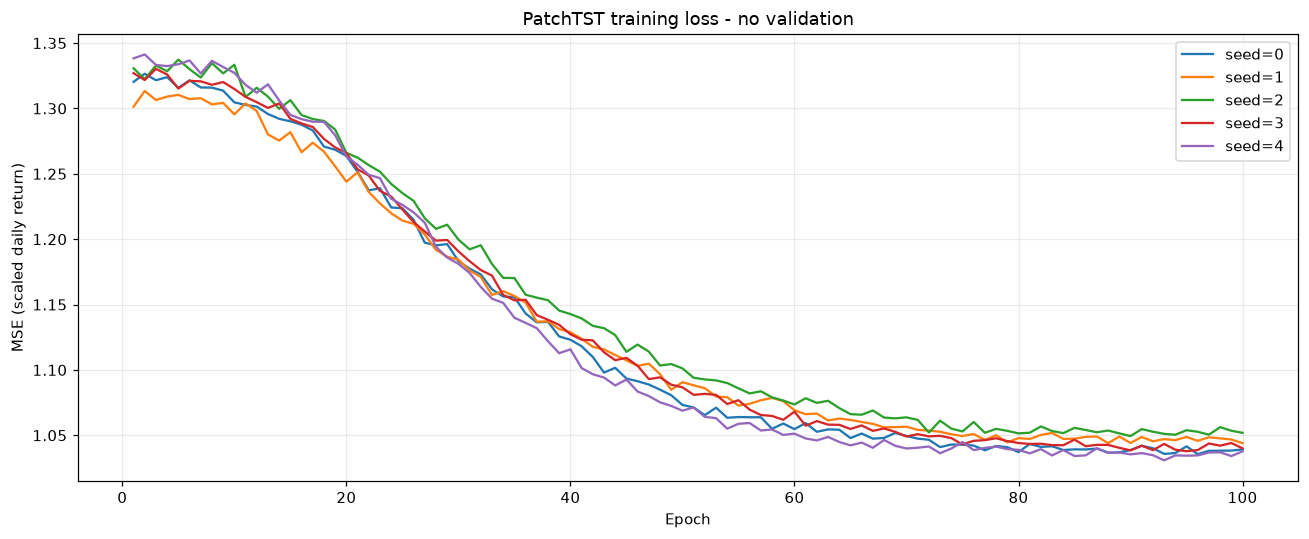

,seed,n_epochs,first_loss,final_loss,loss_reduced,seconds
0,0,100,1.320323,1.039198,True,27.429972
1,1,100,1.301333,1.043978,True,29.522528
2,2,100,1.330718,1.051892,True,27.304533
3,3,100,1.326977,1.040013,True,25.034386
4,4,100,1.338294,1.037782,True,24.948746


In [10]:
models, frozen_weight_hashes, training_rows, training_audit_rows, lr_rows = {}, {}, [], [], []
train_dataset = TensorDataset(torch.from_numpy(X_train),torch.from_numpy(y_train))
for seed in SEEDS:
    set_seed(seed)
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,
        generator=generator,num_workers=0,drop_last=False)
    model = PatchTST().to(DEVICE)
    optimizer = Adam(model.parameters(),lr=LR)
    scheduler = OneCycleLR(optimizer,max_lr=LR,pct_start=PCT_START,
        epochs=EPOCHS,steps_per_epoch=len(train_loader))
    loss_fn = nn.MSELoss()
    epoch_losses=[]
    started=time.perf_counter()
    print(f'Training seed={seed}: {EPOCHS} fixed epochs',flush=True)
    for epoch in range(1,EPOCHS+1):
        model.train()
        total_loss=0.0
        total_samples=0
        for inputs,targets in train_loader:
            inputs,targets=inputs.to(DEVICE),targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            predicted=model(inputs)
            loss=loss_fn(predicted,targets)
            assert torch.isfinite(loss), f'Non-finite Train loss: seed={seed}, epoch={epoch}'
            loss.backward()
            lr_rows.append(dict(seed=seed,step=len(lr_rows)+1,learning_rate=optimizer.param_groups[0]['lr']))
            optimizer.step()
            scheduler.step()
            total_loss+=loss.item()*len(inputs)
            total_samples+=len(inputs)
        epoch_loss=total_loss/total_samples
        epoch_losses.append(epoch_loss)
        training_rows.append(dict(seed=seed,epoch=epoch,loss=epoch_loss))
        if epoch%20==0: print(f'  seed={seed} epoch={epoch}: Train MSE={epoch_loss:.6f}',flush=True)
    model.eval()
    models[seed]=model
    frozen_weight_hashes[seed]=weights_digest(model)
    torch.save(model.state_dict(),MODEL_DIR/f'patchtst_seed{seed}.pt')
    training_audit_rows.append(dict(seed=seed,n_epochs=len(epoch_losses),
        first_loss=epoch_losses[0],final_loss=epoch_losses[-1],
        loss_reduced=epoch_losses[-1]<epoch_losses[0],seconds=time.perf_counter()-started))
    print(f'Saved seed={seed}; Train MSE {epoch_losses[0]:.6f} -> {epoch_losses[-1]:.6f}',flush=True)
training_loss=pd.DataFrame(training_rows)
training_audit=pd.DataFrame(training_audit_rows)
save_table(training_loss,'training_loss.csv')
save_table(training_audit,'training_audit.csv')
save_table(pd.DataFrame(lr_rows),'learning_rate_schedule.csv')
assert len(training_loss)==len(SEEDS)*EPOCHS
fig,ax=plt.subplots()
for seed in SEEDS:
    group=training_loss.loc[training_loss.seed.eq(seed)]
    ax.plot(group.epoch,group.loss,label=f'seed={seed}')
ax.set(title='PatchTST training loss - no validation',xlabel='Epoch',ylabel='MSE (scaled daily return)')
ax.legend(); save_figure(fig,'06_training_loss.png')
display(training_audit)

## Step 9 - Rolling-origin forecasting with fixed weights
All 380 Test origins plus the latest observed origin are predicted in one batch per seed in eval/no_grad mode. No future observations enter an origin's input. Ensemble averaging occurs in daily-return space before cumulative sums and exponentiation; it is not an average of forecast prices. BatchNorm running buffers and learned parameters are hashed before and after inference.

In [11]:
test_origins = np.arange(TRAIN_END_IDX, n-1)
inference_origins = np.r_[test_origins, n-1]
inference_input_indices = inference_origins[:, None] - np.arange(LOOKBACK-1, -1, -1)[None, :]
assert len(test_origins) == n_test
assert inference_input_indices.min() >= 1
assert (inference_input_indices <= inference_origins[:, None]).all()
X_inference = z[inference_input_indices][..., None].astype(np.float32)
assert X_inference.shape == (n_test+1, LOOKBACK, 1) and np.isfinite(X_inference).all()
return_predictions = []
weight_audit_rows = []
for seed in SEEDS:
    assert weights_digest(models[seed]) == frozen_weight_hashes[seed]
    models[seed].eval()
    with torch.no_grad():
        predicted_z = models[seed](torch.from_numpy(X_inference).to(DEVICE)).cpu().numpy().astype(np.float64)
    assert predicted_z.shape == (len(inference_origins), MAX_H)
    predicted_returns = predicted_z * scaler_std + scaler_mean
    np.testing.assert_allclose(predicted_returns,
        scaler.inverse_transform(predicted_z.reshape(-1,1)).reshape(predicted_z.shape), atol=1e-12)
    return_predictions.append(predicted_returns)
    after = weights_digest(models[seed])
    assert after == frozen_weight_hashes[seed], 'Weights changed during inference'
    weight_audit_rows.append(dict(seed=seed, train_hash=frozen_weight_hashes[seed],
        after_predict_hash=after, unchanged=after == frozen_weight_hashes[seed]))
return_predictions = np.stack(return_predictions, axis=0)
return_predictions_ens = return_predictions.mean(axis=0)
origin_prices = df['Price'].iloc[inference_origins].to_numpy()
seed_prices = origin_prices[None, :, None] * np.exp(np.cumsum(return_predictions, axis=2))
ensemble_prices = origin_prices[:, None] * np.exp(np.cumsum(return_predictions_ens, axis=1))
forecast_rows = []
for h in HORIZONS:
    eligible = np.flatnonzero(test_origins + h < n)
    for pos in eligible:
        origin = int(test_origins[pos])
        target = origin + h
        row = dict(origin_date=df.index[origin], h=h, target_date=df.index[target],
            price_origin=df['Price'].iloc[origin], actual=df['Price'].iloc[target],
            patchtst_fc_ens=ensemble_prices[pos, h-1])
        row.update({f'patchtst_fc_seed{seed}': seed_prices[k, pos, h-1] for k,seed in enumerate(SEEDS)})
        forecast_rows.append(row)
forecasts = pd.DataFrame(forecast_rows).sort_values(['h','target_date']).reset_index(drop=True)
assert forecasts.groupby('h').size().to_dict() == {h:n_test-h+1 for h in HORIZONS}
assert not forecasts.duplicated(['origin_date','h']).any()
assert (forecasts['target_date'] >= df.index[n_train]).all()
assert ((forecasts['target_date']-forecasts['origin_date']).dt.days == forecasts['h']).all()
save_table(forecasts, 'forecasts_long.csv')
weight_audit = pd.DataFrame(weight_audit_rows)
save_table(weight_audit, 'weights_fixed_audit.csv')
display(forecasts.groupby('h').size().rename('n_points').to_frame())

,n_points
h,
1,380
3,378
5,376
7,374
14,367
21,360
30,351


### Step 9.1 - Historical Test forecast tables by horizon
`origin_date` is the last known observation. `target_date = origin_date + h` lies inside Test; `actual` is used only to evaluate the forecast. All rows are exported, with scrollable notebook displays.

In [12]:
for h in HORIZONS:
    horizon_forecasts = forecasts.loc[forecasts['h'].eq(h)].copy()
    save_table(horizon_forecasts, f'forecasts_h{h}.csv')
    display(Markdown(f'**h = {h} calendar days: {len(horizon_forecasts)} test forecasts**'))
    show_scroll_table(horizon_forecasts)

**h = 1 calendar days: 380 test forecasts**

origin_date,h,target_date,price_origin,actual,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2025-08-25,1,2025-08-26,"110,118.40","111,768.60","109,900.37","109,807.46","110,286.85","109,536.99","109,720.02","110,152.29"
2025-08-26,1,2025-08-27,"111,768.60","111,255.60","111,861.89","111,884.97","112,084.62","111,475.14","111,922.76","111,942.87"
2025-08-27,1,2025-08-28,"111,255.60","112,568.90","111,178.56","111,297.52","110,741.86","111,423.19","110,876.09","111,556.36"
2025-08-28,1,2025-08-29,"112,568.90","108,355.60","112,492.17","112,349.52","112,762.28","111,963.66","112,578.03","112,809.48"
2025-08-29,1,2025-08-30,"108,355.60","108,818.10","108,353.82","108,111.95","108,312.80","108,567.25","108,483.75","108,293.95"
2025-08-30,1,2025-08-31,"108,818.10","108,226.80","109,201.65","109,216.00","109,092.01","109,353.45","109,006.68","109,340.55"
2025-08-31,1,2025-09-01,"108,226.80","109,243.30","107,940.21","108,283.37","107,633.34","108,043.17","107,800.57","107,941.71"
2025-09-01,1,2025-09-02,"109,243.30","111,218.30","109,045.65","108,897.39","109,068.79","108,670.20","109,522.37","109,071.32"
2025-09-02,1,2025-09-03,"111,218.30","111,716.50","111,247.95","111,165.38","111,040.26","111,370.66","111,424.33","111,239.53"
2025-09-03,1,2025-09-04,"111,716.50","110,712.70","112,000.33","112,227.78","111,841.58","111,759.68","112,234.04","111,939.41"


**h = 3 calendar days: 378 test forecasts**

origin_date,h,target_date,price_origin,actual,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2025-08-25,3,2025-08-28,"110,118.40","112,568.90","109,524.78","109,622.21","108,902.91","109,388.80","109,289.20","110,426.65"
2025-08-26,3,2025-08-29,"111,768.60","108,355.60","112,254.59","111,823.90","113,146.84","111,314.86","112,351.44","112,644.95"
2025-08-27,3,2025-08-30,"111,255.60","108,818.10","111,506.56","111,702.01","110,867.53","112,547.21","110,588.05","111,839.12"
2025-08-28,3,2025-08-31,"112,568.90","108,226.80","112,763.69","112,380.01","113,177.24","112,177.88","112,815.78","113,271.65"
2025-08-29,3,2025-09-01,"108,355.60","109,243.30","108,437.32","108,424.05","107,889.59","108,761.77","108,601.46","108,511.76"
2025-08-30,3,2025-09-02,"108,818.10","111,218.30","109,187.43","109,340.90","109,038.25","109,622.08","108,934.09","109,003.34"
2025-08-31,3,2025-09-03,"108,226.80","111,716.50","107,864.61","108,159.85","107,447.75","108,387.39","107,273.93","108,058.41"
2025-09-01,3,2025-09-04,"109,243.30","110,712.70","109,485.43","109,311.16","109,224.49","108,768.38","110,496.24","109,634.42"
2025-09-02,3,2025-09-05,"111,218.30","110,652.20","111,440.65","111,610.67","110,964.59","111,531.63","111,708.25","111,389.62"
2025-09-03,3,2025-09-06,"111,716.50","110,194.40","112,205.91","112,345.86","112,130.86","112,169.08","112,485.00","111,899.65"


**h = 5 calendar days: 376 test forecasts**

...

origin_date,h,target_date,price_origin,actual,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2025-08-25,14,2025-09-08,"110,118.40","112,068.40","110,014.06","110,832.92","109,112.28","109,895.64","108,696.87","111,558.09"
2025-08-26,14,2025-09-09,"111,768.60","111,516.50","112,987.08","112,103.23","113,924.15","113,364.16","112,647.12","112,905.24"
2025-08-27,14,2025-09-10,"111,255.60","113,963.50","111,771.45","112,219.26","112,515.74","111,467.21","111,098.09","111,562.94"
2025-08-28,14,2025-09-11,"112,568.90","115,490.20","113,817.03","112,903.45","114,215.84","113,631.64","113,441.14","114,903.38"
2025-08-29,14,2025-09-12,"108,355.60","116,042.80","108,629.58","108,694.10","107,469.49","109,989.66","109,056.04","107,956.25"
2025-08-30,14,2025-09-13,"108,818.10","115,924.90","110,070.05","110,349.80","109,367.17","111,543.60","109,925.30","109,180.48"
2025-08-31,14,2025-09-14,"108,226.80","115,314.60","107,318.43","107,311.85","107,100.33","107,418.81","107,547.94","107,213.80"
2025-09-01,14,2025-09-15,"109,243.30","115,362.10","108,820.36","109,949.62","107,908.01","106,998.22","109,684.06","109,593.13"
2025-09-02,14,2025-09-16,"111,218.30","116,795.90","112,489.80","113,705.16","110,797.47","112,532.61","113,443.35","111,994.89"
2025-09-03,14,2025-09-17,"111,716.50","116,425.90","113,152.06","112,900.61","114,917.96","113,251.13","112,676.66","112,034.48"


**h = 21 calendar days: 360 test forecasts**

origin_date,h,target_date,price_origin,actual,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2025-08-25,21,2025-09-15,"110,118.40","115,362.10","110,204.30","111,962.14","109,539.20","109,284.85","108,350.74","111,933.51"
2025-08-26,21,2025-09-16,"111,768.60","116,795.90","114,018.32","112,597.83","115,145.26","114,864.33","113,741.45","113,760.94"
2025-08-27,21,2025-09-17,"111,255.60","116,425.90","112,626.43","113,362.91","112,298.81","112,660.18","112,449.86","112,363.71"
2025-08-28,21,2025-09-18,"112,568.90","117,086.00","114,667.24","112,807.70","115,413.45","114,662.21","114,582.18","115,894.89"
2025-08-29,21,2025-09-19,"108,355.60","115,649.00","109,729.46","109,920.41","109,081.94","111,180.14","109,649.89","108,830.23"
2025-08-30,21,2025-09-20,"108,818.10","115,699.20","111,203.46","112,580.47","109,843.14","112,828.44","110,523.45","110,276.36"
2025-08-31,21,2025-09-21,"108,226.80","115,243.00","106,930.13","107,069.33","105,930.90","105,992.38","108,055.74","107,619.34"
2025-09-01,21,2025-09-22,"109,243.30","112,673.00","108,341.82","108,773.90","107,117.76","106,799.91","109,889.07","109,161.40"
2025-09-02,21,2025-09-23,"111,218.30","112,002.60","112,535.33","114,143.14","110,031.88","112,577.44","113,873.10","112,099.47"
2025-09-03,21,2025-09-24,"111,716.50","113,307.10","113,178.64","112,950.11","116,230.01","112,365.63","111,953.93","112,446.15"


**h = 30 calendar days: 351 test forecasts**

origin_date,h,target_date,price_origin,actual,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2025-08-25,30,2025-09-24,"110,118.40","113,307.10","110,770.65","112,322.00","109,078.86","111,382.01","108,931.00","112,189.33"
2025-08-26,30,2025-09-25,"111,768.60","109,016.30","114,139.21","112,167.88","115,967.82","115,450.27","112,949.90","114,205.63"
2025-08-27,30,2025-09-26,"111,255.60","109,662.20","112,921.04","113,066.65","112,336.01","112,084.28","113,456.14","113,670.59"
2025-08-28,30,2025-09-27,"112,568.90","109,652.80","114,642.32","113,020.89","114,171.78","114,429.27","114,262.87","117,372.15"
2025-08-29,30,2025-09-28,"108,355.60","112,174.60","109,551.53","110,075.63","108,037.94","111,928.37","108,808.98","108,948.16"
2025-08-30,30,2025-09-29,"108,818.10","114,357.50","111,687.70","113,411.26","109,742.11","113,845.97","111,125.50","110,373.77"
2025-08-31,30,2025-09-30,"108,226.80","114,048.50","106,611.46","106,215.98","106,531.69","105,264.20","106,594.85","108,476.04"
2025-09-01,30,2025-10-01,"109,243.30","118,576.20","107,631.14","108,476.60","105,952.00","105,579.00","109,561.71","108,644.59"
2025-09-02,30,2025-10-02,"111,218.30","120,566.10","113,942.35","115,290.25","112,374.87","114,224.21","114,244.18","113,598.30"
2025-09-03,30,2025-10-03,"111,716.50","122,224.20","113,676.19","113,068.72","116,728.19","113,153.39","113,263.53","112,220.39"


### Step 9.2 - Future forecasts from the latest observation
All horizons share the final observed origin, using the fixed original Train weights. Future target dates have no actual values or error metrics yet. Explicit NumPy day units avoid the previously encountered timedelta warning.

In [13]:
future_rows = []
latest_origin = df.index[-1]
for h in HORIZONS:
    row = dict(origin_date=latest_origin, h=h, target_date=pd.Timestamp(latest_origin.to_datetime64()+np.timedelta64(int(h),'D')),
        price_origin=float(df['Price'].iloc[-1]), patchtst_fc_ens=ensemble_prices[-1,h-1])
    row.update({f'patchtst_fc_seed{seed}': seed_prices[k,-1,h-1] for k,seed in enumerate(SEEDS)})
    future_rows.append(row)
future_forecasts = pd.DataFrame(future_rows)
assert (future_forecasts['target_date'] > df.index[-1]).all()
save_table(future_forecasts, 'future_forecast_by_horizon.csv')
show_scroll_table(future_forecasts)

origin_date,h,target_date,price_origin,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2026-09-09,1,2026-09-10,"78,297.00","78,453.80","78,602.78","78,742.29","78,093.42","78,547.87","78,284.37"
2026-09-09,3,2026-09-12,"78,297.00","79,109.24","78,986.37","79,725.13","78,781.15","79,356.33","78,701.79"
2026-09-09,5,2026-09-14,"78,297.00","79,841.79","79,438.02","80,289.31","79,391.66","80,555.76","79,541.50"
2026-09-09,7,2026-09-16,"78,297.00","80,800.05","80,221.54","81,234.91","80,355.06","81,870.09","80,331.52"
2026-09-09,14,2026-09-23,"78,297.00","82,369.78","82,503.49","82,515.14","81,600.53","83,498.94","81,744.69"
2026-09-09,21,2026-09-30,"78,297.00","84,622.88","84,142.74","85,597.65","84,172.70","86,302.13","82,940.71"
2026-09-09,30,2026-10-09,"78,297.00","86,844.38","85,978.08","88,063.07","86,881.26","88,052.81","85,282.06"


### 9.3 Daily future forecast tables - next 7 and 30 calendar days
Reuses the fixed Train ensemble daily-return path and per-seed forecasts. No refitting. Seed spread is not a calibrated prediction interval.

All rows share the last observed origin. Prices are in USD. These models do not supply calibrated 95% prediction intervals.
Exports: `tables/future_forecast_daily_7d.csv` and `tables/future_forecast_daily_30d.csv` under this notebook's output directory.


In [14]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
latest_origin = pd.Timestamp(df.index[-1])
latest_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex([
    pd.Timestamp(latest_origin.to_datetime64() + np.timedelta64(h, 'D'))
    for h in range(1, daily_steps + 1)
])
# Reuse the existing 30-output forecast path; no fitting or new inference.
assert ensemble_prices.shape[1] >= daily_steps
future_forecast_daily = pd.DataFrame(dict(origin_date=latest_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=latest_price,
    patchtst_fc_ens=ensemble_prices[-1, :daily_steps]))
for k, seed in enumerate(SEEDS):
    assert weights_digest(models[seed]) == frozen_weight_hashes[seed]
    future_forecast_daily[f'patchtst_fc_seed{seed}'] = seed_prices[k, -1, :daily_steps]
daily_forecast_columns = ['patchtst_fc_ens', *[f'patchtst_fc_seed{seed}' for seed in SEEDS]]
assert len(future_forecast_daily) == daily_steps
assert ((future_forecast_daily['target_date'] - latest_origin).dt.days == future_forecast_daily['h']).all()
assert not future_forecast_daily['target_date'].duplicated().any()
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(
    future_forecast_daily.set_index('h').loc[HORIZONS, daily_forecast_columns],
    future_forecasts.set_index('h').loc[HORIZONS, daily_forecast_columns], rtol=1e-12)
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} calendar days - origin {latest_origin.date()}, last price {latest_price:,.2f} USD**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.2f}')))


**Next 7 calendar days - origin 2026-09-09, last price 78,297.00 USD**

origin_date,h,target_date,day_of_week,price_origin,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2026-09-09,1,2026-09-10,Thursday,"78,297.00","78,453.80","78,602.78","78,742.29","78,093.42","78,547.87","78,284.37"
2026-09-09,2,2026-09-11,Friday,"78,297.00","78,782.71","78,843.87","79,302.15","78,611.06","78,617.82","78,541.10"
2026-09-09,3,2026-09-12,Saturday,"78,297.00","79,109.24","78,986.37","79,725.13","78,781.15","79,356.33","78,701.79"
2026-09-09,4,2026-09-13,Sunday,"78,297.00","79,484.76","79,166.88","80,256.86","79,159.03","79,701.23","79,145.86"
2026-09-09,5,2026-09-14,Monday,"78,297.00","79,841.79","79,438.02","80,289.31","79,391.66","80,555.76","79,541.50"
2026-09-09,6,2026-09-15,Tuesday,"78,297.00","80,416.55","79,734.62","80,815.57","80,078.56","81,270.10","80,193.30"
2026-09-09,7,2026-09-16,Wednesday,"78,297.00","80,800.05","80,221.54","81,234.91","80,355.06","81,870.09","80,331.52"


**Next 30 calendar days - origin 2026-09-09, last price 78,297.00 USD**

origin_date,h,target_date,day_of_week,price_origin,patchtst_fc_ens,patchtst_fc_seed0,patchtst_fc_seed1,patchtst_fc_seed2,patchtst_fc_seed3,patchtst_fc_seed4
2026-09-09,1,2026-09-10,Thursday,"78,297.00","78,453.80","78,602.78","78,742.29","78,093.42","78,547.87","78,284.37"
2026-09-09,2,2026-09-11,Friday,"78,297.00","78,782.71","78,843.87","79,302.15","78,611.06","78,617.82","78,541.10"
2026-09-09,3,2026-09-12,Saturday,"78,297.00","79,109.24","78,986.37","79,725.13","78,781.15","79,356.33","78,701.79"
2026-09-09,4,2026-09-13,Sunday,"78,297.00","79,484.76","79,166.88","80,256.86","79,159.03","79,701.23","79,145.86"
2026-09-09,5,2026-09-14,Monday,"78,297.00","79,841.79","79,438.02","80,289.31","79,391.66","80,555.76","79,541.50"
2026-09-09,6,2026-09-15,Tuesday,"78,297.00","80,416.55","79,734.62","80,815.57","80,078.56","81,270.10","80,193.30"
2026-09-09,7,2026-09-16,Wednesday,"78,297.00","80,800.05","80,221.54","81,234.91","80,355.06","81,870.09","80,331.52"
2026-09-09,8,2026-09-17,Thursday,"78,297.00","81,013.53","80,710.90","81,643.57","80,501.97","82,038.60","80,187.88"
2026-09-09,9,2026-09-18,Friday,"78,297.00","81,086.08","80,749.49","81,665.41","80,591.72","82,208.84","80,231.46"
2026-09-09,10,2026-09-19,Saturday,"78,297.00","81,255.16","80,924.89","81,778.60","80,475.72","82,705.12","80,414.74"


## Step 10 - Forecast sanity checks and USD evaluation
Check every ensemble and seed forecast for finite, positive values and the specified 0.5-2 times origin-price range. Stop and display/export offending rows if a check fails; no clipping or retuning. RMSE is in USD; MAPE is percent. Seed variability uses sample SD (ddof=1), not uncertainty intervals.

In [15]:
forecast_columns = ['patchtst_fc_ens', *[f'patchtst_fc_seed{seed}' for seed in SEEDS]]
for name, frame in [('test', forecasts), ('future', future_forecasts)]:
    values = frame[forecast_columns].to_numpy()
    ratios = values / frame['price_origin'].to_numpy()[:,None]
    bad = (~np.isfinite(values)) | (values <= 0) | (ratios < 0.5) | (ratios > 2)
    if bad.any():
        bad_rows = frame.loc[bad.any(axis=1)].copy()
        print(f'Invalid {name} forecasts; stop without clipping or retuning.')
        display(bad_rows)
        save_table(bad_rows, f'forecast_sanity_failures_{name}.csv')
    assert not bad.any(), f'{name} forecasts fail the specified positive/finite/0.5-2x origin-price bounds'

def rmse(actual, fc):
    actual, fc = np.asarray(actual, dtype=float), np.asarray(fc, dtype=float)
    return float(np.sqrt(np.mean((actual-fc)**2)))
def mape(actual, fc):
    actual, fc = np.asarray(actual, dtype=float), np.asarray(fc, dtype=float)
    assert (actual > 0).all()
    return float(100*np.mean(np.abs((actual-fc)/actual)))
evaluation_rows, seed_rows = [], []
for h in HORIZONS:
    group = forecasts.loc[forecasts['h'].eq(h)]
    evaluation_rows.append(dict(h=h, n_points=len(group),
        RMSE=rmse(group['actual'], group['patchtst_fc_ens']), MAPE=mape(group['actual'], group['patchtst_fc_ens'])))
    for seed in SEEDS:
        seed_rows.append(dict(h=h, seed=seed, RMSE=rmse(group['actual'], group[f'patchtst_fc_seed{seed}']),
                              MAPE=mape(group['actual'], group[f'patchtst_fc_seed{seed}'])))
evaluation = pd.DataFrame(evaluation_rows)
evaluation_seed_individual = pd.DataFrame(seed_rows)
seed_summary_rows, seed_export_rows = [], []
for h in HORIZONS:
    group = evaluation_seed_individual.loc[evaluation_seed_individual['h'].eq(h)]
    mean = group[['RMSE','MAPE']].mean()
    sd = group[['RMSE','MAPE']].std(ddof=1)
    seed_summary_rows.append(dict(h=h, RMSE_mean=mean['RMSE'], RMSE_SD=sd['RMSE'],
                                  MAPE_mean=mean['MAPE'], MAPE_SD=sd['MAPE']))
    seed_export_rows.extend(group.to_dict('records'))
    seed_export_rows.extend([dict(h=h, seed='mean', **mean.to_dict()), dict(h=h, seed='SD', **sd.to_dict())])
seed_summary = pd.DataFrame(seed_summary_rows)
evaluation_by_seed = pd.DataFrame(seed_export_rows)
assert evaluation['h'].tolist() == HORIZONS
save_table(evaluation, 'evaluation_by_horizon.csv')
save_table(evaluation_by_seed, 'evaluation_by_seed.csv')
print('Ensemble RMSE (USD), MAPE (%):')
display(evaluation.style.format({'RMSE':'{:,.2f}', 'MAPE':'{:.2f}'}).hide(axis='index'))
print('Mean and SD across seeds (not ensemble metrics):')
display(seed_summary)

Ensemble RMSE (USD), MAPE (%):


h,n_points,RMSE,MAPE
1,380,"1,878.44",1.63
3,378,"3,359.16",3.10
5,376,"4,417.14",4.04
7,374,"5,431.70",5.05
14,367,"8,182.76",8.13
21,360,"10,607.91",11.10
30,351,"13,612.49",15.52


Mean and SD across seeds (not ensemble metrics):


,h,RMSE_mean,RMSE_SD,MAPE_mean,MAPE_SD
0,1,1891.627416,12.934546,1.648034,0.012229
1,3,3381.465734,19.630188,3.117560,0.034895
2,5,4446.733617,36.007700,4.067472,0.051768
3,7,5467.274696,31.467829,5.093884,0.045031
4,14,8224.885267,41.718032,8.188100,0.058423
5,21,10655.100593,17.744365,11.140559,0.033878
6,30,13657.472053,30.259211,15.528991,0.046239


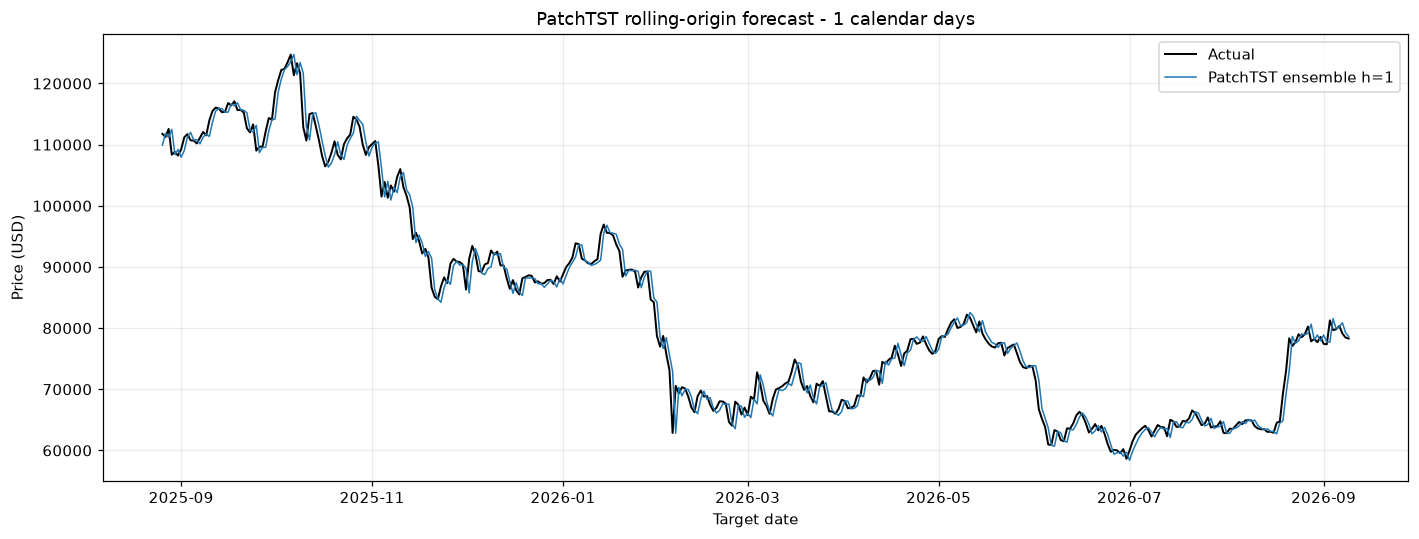

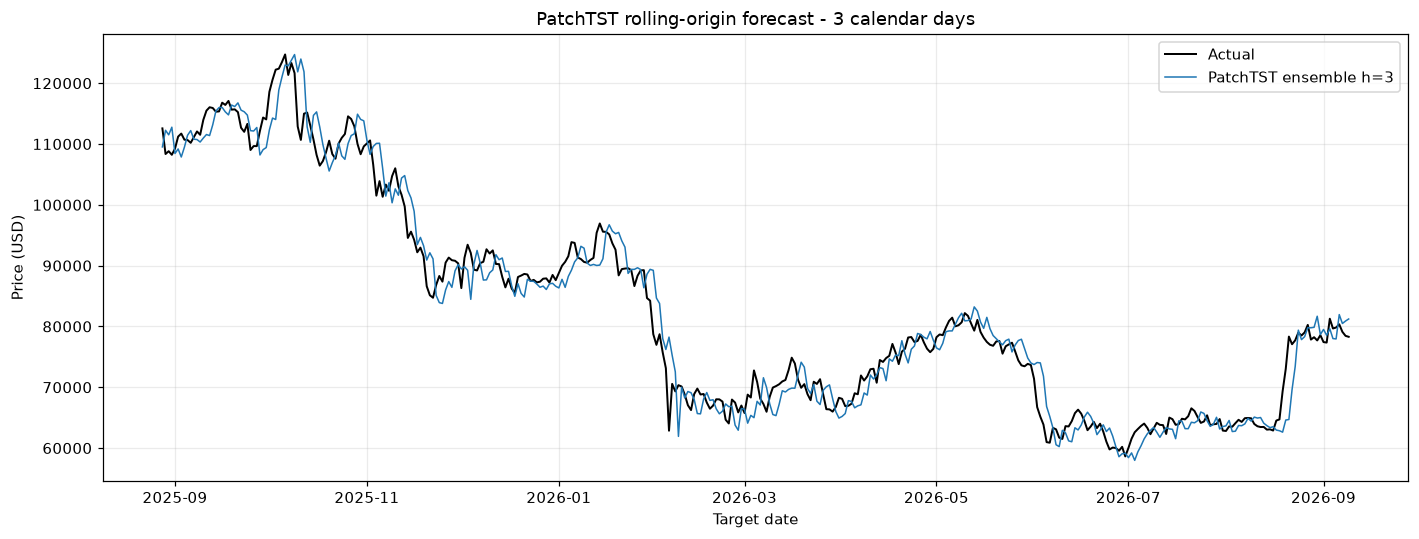

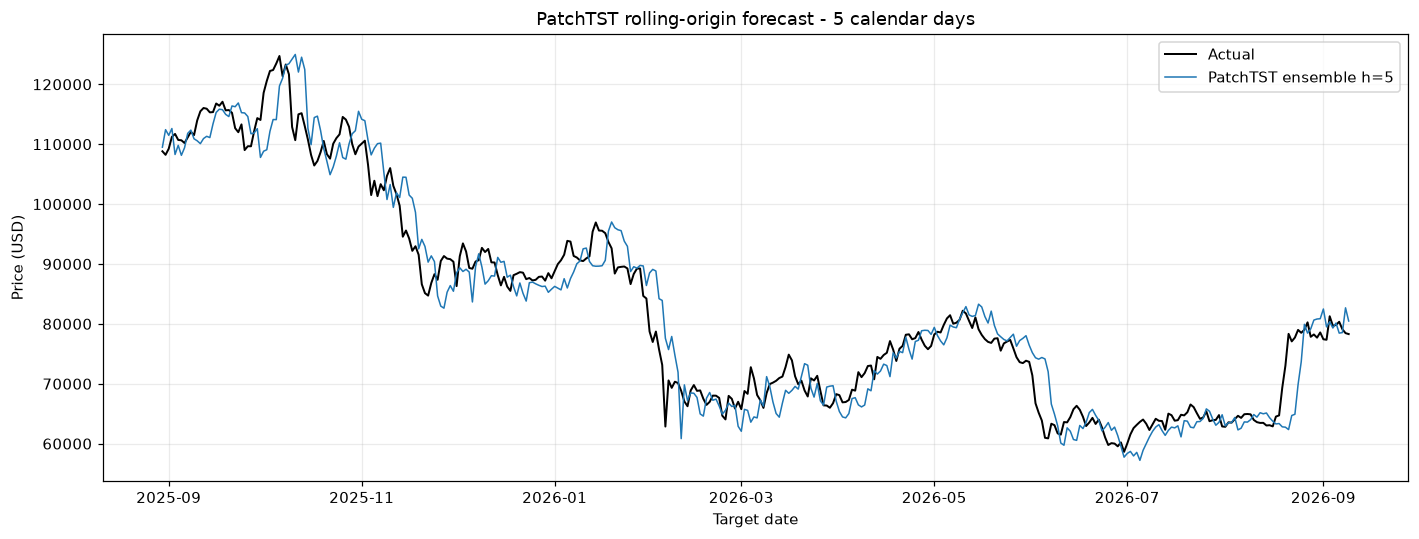

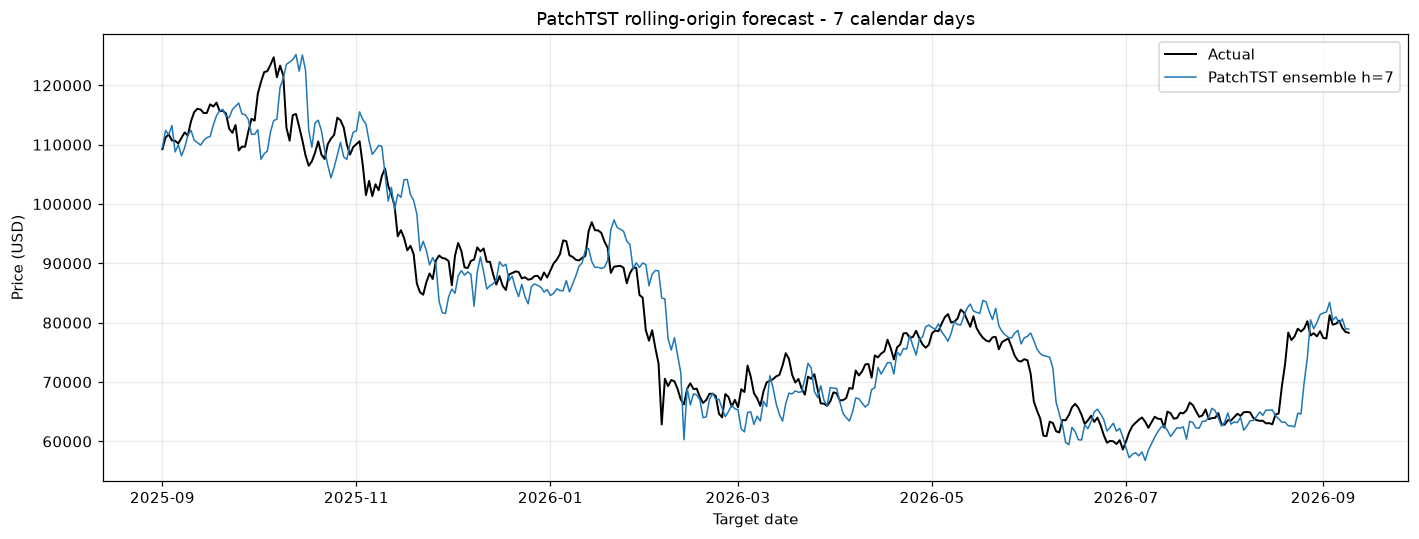

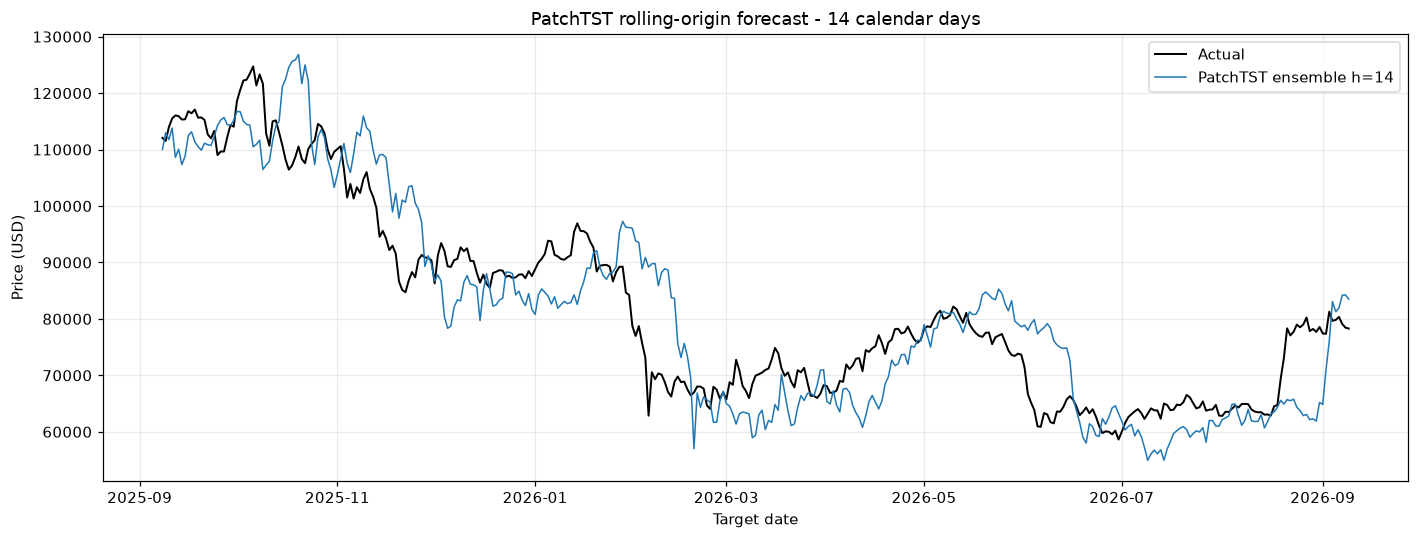

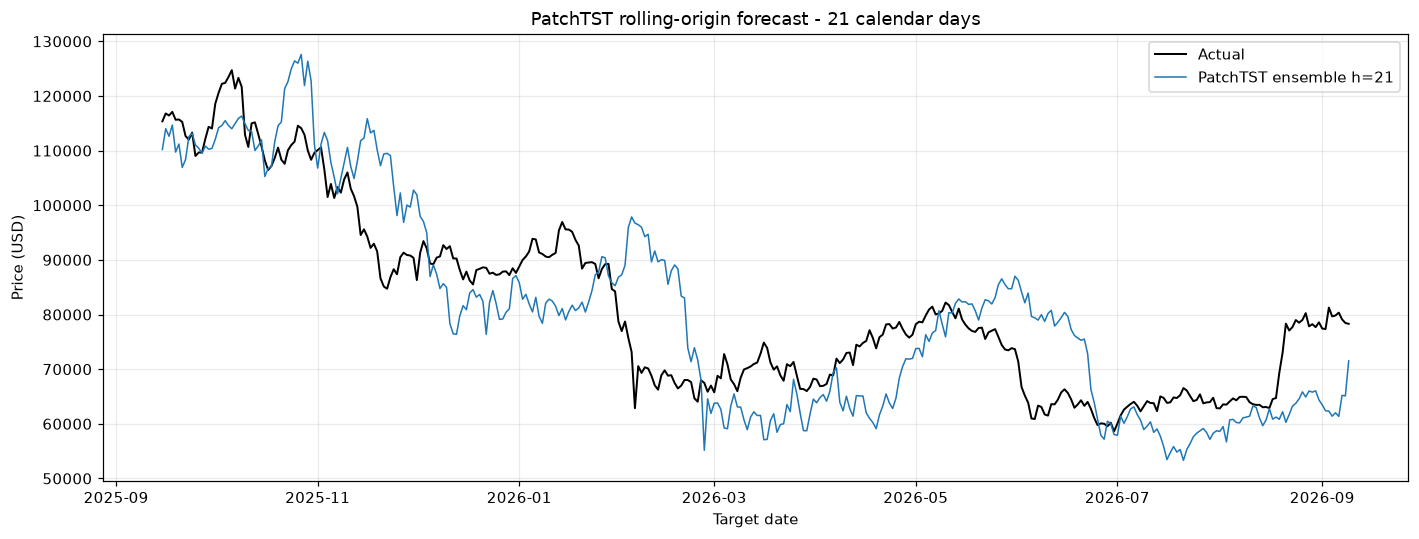

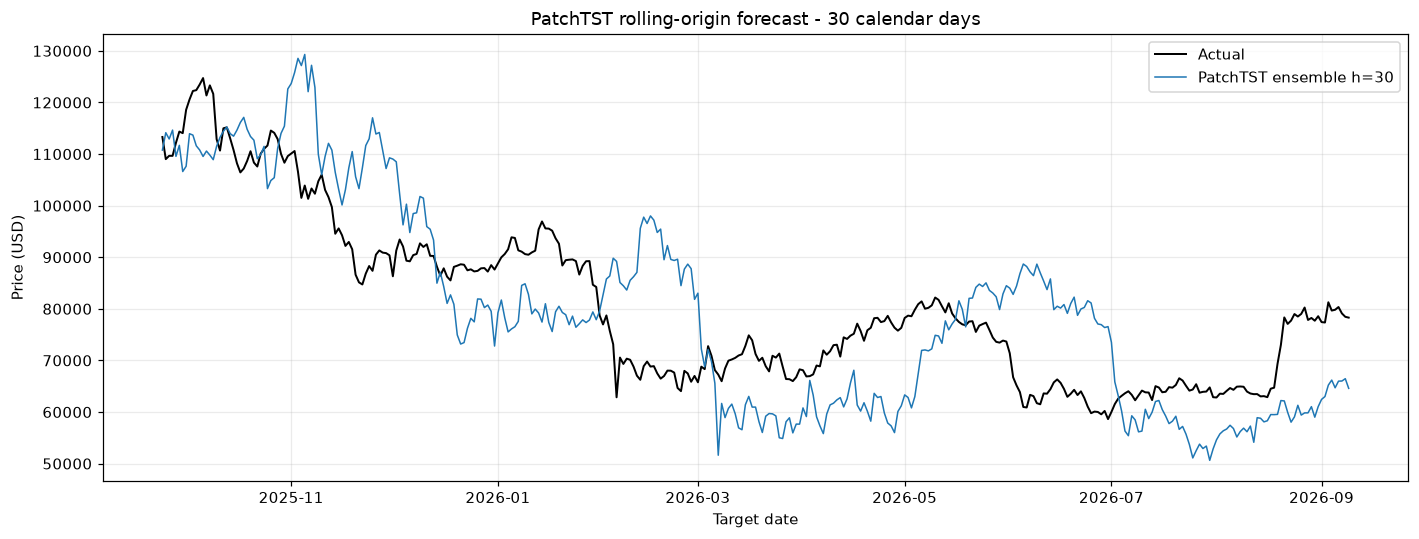

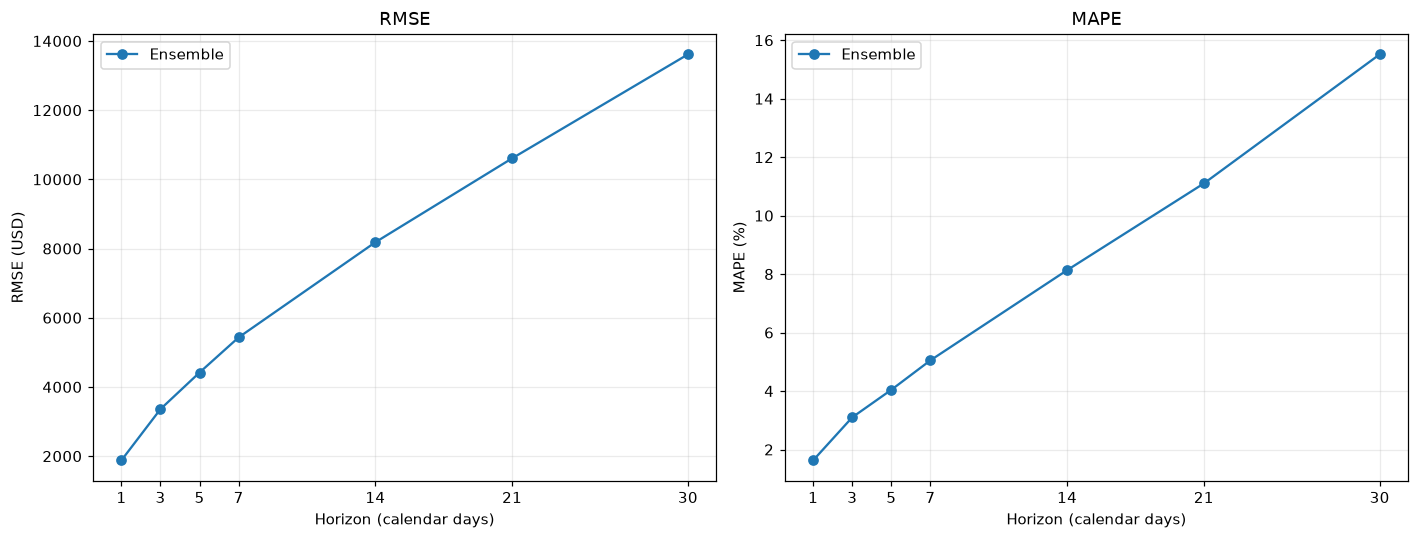

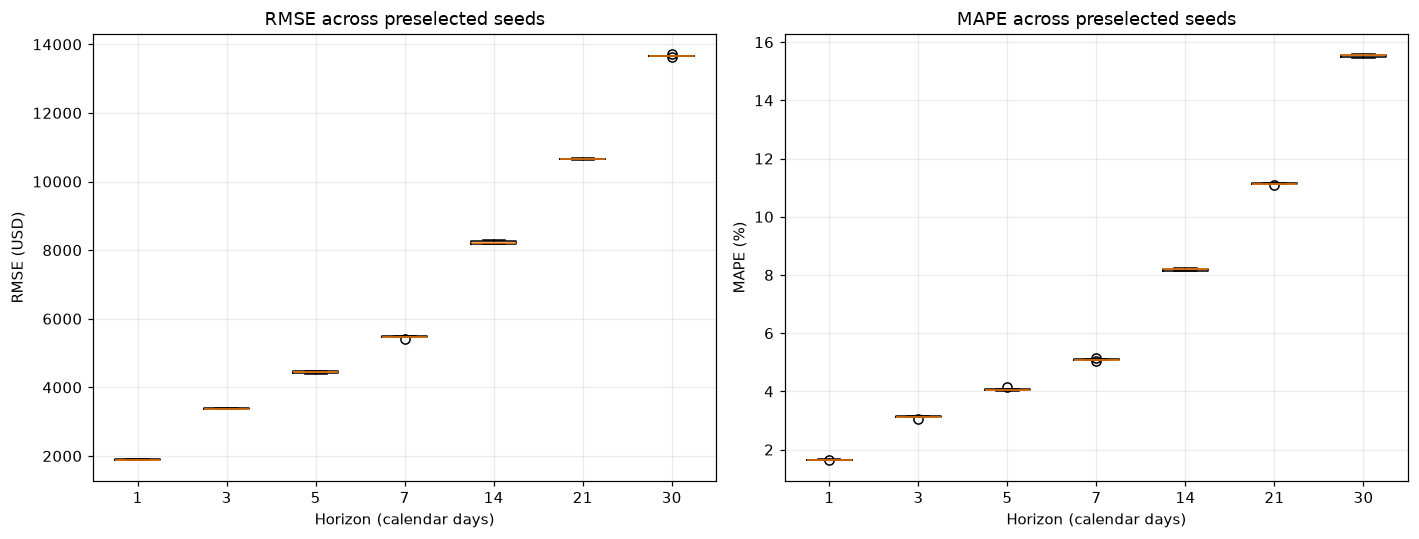

In [16]:
for h in HORIZONS:
    group = forecasts.loc[forecasts['h'].eq(h)]
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(group['target_date'], group['actual'], color='black', label='Actual', linewidth=1.3)
    ax.plot(group['target_date'], group['patchtst_fc_ens'], label=f'PatchTST ensemble h={h}', linewidth=1)
    ax.set(title=f'PatchTST rolling-origin forecast - {h} calendar days', ylabel='Price (USD)', xlabel='Target date')
    ax.legend()
    save_figure(fig, f'07_forecast_h{h}.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, unit in zip(axes, ['RMSE','MAPE'], ['USD','%']):
    ax.plot(evaluation['h'], evaluation[metric], marker='o', label='Ensemble')
    ax.set(title=metric, xlabel='Horizon (calendar days)', ylabel=f'{metric} ({unit})', xticks=HORIZONS)
    ax.legend()
save_figure(fig, '08_error_vs_horizon.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, unit in zip(axes, ['RMSE','MAPE'], ['USD','%']):
    values = [evaluation_seed_individual.loc[evaluation_seed_individual['h'].eq(h),metric].to_numpy()
              for h in HORIZONS]
    ax.boxplot(values, tick_labels=[str(h) for h in HORIZONS])
    ax.set(title=f'{metric} across preselected seeds', xlabel='Horizon (calendar days)', ylabel=f'{metric} ({unit})')
save_figure(fig, '09_seed_variability.png')

## Step 11 - Process assumptions and residual diagnostics
Group A chronology, leakage, scaler provenance, patch geometry, fixed weights and reduction in training loss are enforced. Return-scale comparisons, parameters relative to training samples and variability across seeds are reported descriptively because no acceptable threshold was specified. They do not prove the absence of overfitting.

Group B uses h=1 Test ensemble daily-return residuals only. Significant p-values describe limitations without changing the trained models; higher-horizon errors overlap naturally.

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,group,check,statistic,p_value,pass/fail,note
0,A,Chronological unique dates,1.000000,NaN,PASS,
1,A,Train windows exclude test,1516.000000,NaN,PASS,All inputs/targets <= 1516
2,A,Scaler fit excludes test,1516.000000,NaN,PASS,
3,A,Fixed inference weights,1.000000,NaN,PASS,
4,A,Train/test return mean and SD,0.804468,NaN,REPORTED,"Train mean=0.00078411, SD=0.0284756; Test mean..."
5,A,Training loss reduced: seed 0,0.787079,NaN,PASS,First=1.32032; final=1.0392; fixed 100 epochs
6,A,Training loss reduced: seed 1,0.802237,NaN,PASS,First=1.30133; final=1.04398; fixed 100 epochs
7,A,Training loss reduced: seed 2,0.790469,NaN,PASS,First=1.33072; final=1.05189; fixed 100 epochs
8,A,Training loss reduced: seed 3,0.783746,NaN,PASS,First=1.32698; final=1.04001; fixed 100 epochs
9,A,Training loss reduced: seed 4,0.775452,NaN,PASS,First=1.33829; final=1.03778; fixed 100 epochs


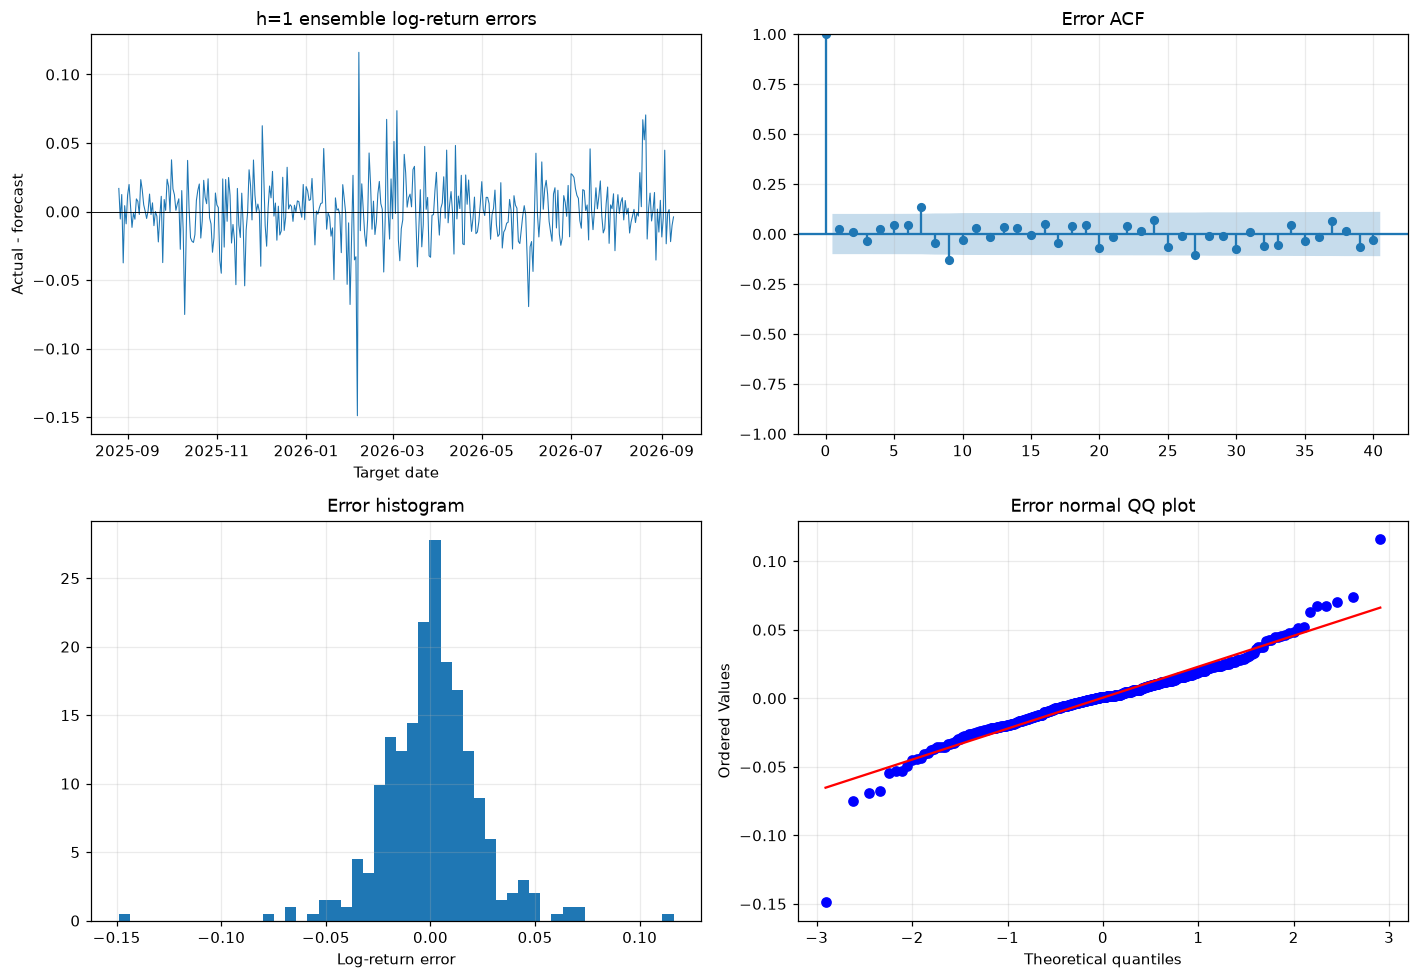

In [17]:
check_rows = []
def add_check(group, check, statistic=np.nan, p_value=np.nan, passed=None, note=''):
    status = 'REPORTED' if passed is None else ('PASS' if bool(passed) else 'FAIL')
    check_rows.append({'group':group, 'check':check, 'statistic':statistic,
                       'p_value':p_value, 'pass/fail':status, 'note':note})
ordered = df.index.is_monotonic_increasing and df.index.is_unique
no_leak = train_input_indices.max() <= TRAIN_END_IDX and train_target_indices.max() <= TRAIN_END_IDX
scaler_train_only = scaler_fit_indices.max() <= TRAIN_END_IDX and int(scaler.n_samples_seen_) == n_train-1
add_check('A','Chronological unique dates', int(ordered), passed=ordered)
add_check('A','Train windows exclude test', int(train_target_indices.max()), passed=no_leak,
          note=f'All inputs/targets <= {TRAIN_END_IDX}')
add_check('A','Scaler fit excludes test', int(scaler_fit_indices.max()), passed=scaler_train_only)
add_check('A','Fixed inference weights', int(weight_audit['unchanged'].all()), passed=weight_audit['unchanged'].all())
train_stats = split_summary.set_index('split').loc['Train']
test_stats = split_summary.set_index('split').loc['Test']
add_check('A','Train/test return mean and SD', float(test_stats['log_ret_std']/train_stats['log_ret_std']),
    note=f'Train mean={train_stats["log_ret_mean"]:.6g}, SD={train_stats["log_ret_std"]:.6g}; '
         f'Test mean={test_stats["log_ret_mean"]:.6g}, SD={test_stats["log_ret_std"]:.6g}. '
         'Statistic=Test/Train SD ratio; no acceptance threshold specified.')
for row in training_audit.itertuples(index=False):
    add_check('A',f'Training loss reduced: seed {row.seed}', row.final_loss/row.first_loss,
        passed=row.loss_reduced, note=f'First={row.first_loss:.6g}; final={row.final_loss:.6g}; fixed {EPOCHS} epochs')
for row in seed_summary.itertuples(index=False):
    add_check('A',f'Seed RMSE SD: h={row.h}', row.RMSE_SD,
              note=f'USD, sample SD across {len(SEEDS)} seeds; no threshold specified')
    add_check('A',f'Seed MAPE SD: h={row.h}', row.MAPE_SD,
              note=f'Percentage points, sample SD across {len(SEEDS)} seeds; no threshold specified')
patching_ok = patch_count==7 and PATCH_LEN==16 and patches.shape[-2:]==(7,16)
add_check('A','Correct patch count and length',patch_count,passed=patching_ok,note='7 patches, each 16 values')
add_check('A','Parameters relative to training samples',parameter_count/len(X_train),
    note=f'{parameter_count} trainable parameters vs {len(X_train)} windows; windows overlap; no pass threshold; overfit risk')
assert patching_ok
assert ordered and no_leak and scaler_train_only and weight_audit['unchanged'].all()
assert np.isfinite(seed_summary.select_dtypes('number').to_numpy()).all()

error_dates = df.index[test_origins+1]
e = log_ret.iloc[test_origins+1].to_numpy() - return_predictions_ens[:len(test_origins),0]
assert len(e) == n_test == 380 and np.isfinite(e).all()
ljung_box = acorr_ljungbox(e, lags=[10,20,30], return_df=True)
for lag,row in ljung_box.iterrows():
    add_check('B',f'Ljung-Box lag {lag}', row['lb_stat'], row['lb_pvalue'], row['lb_pvalue'] > ALPHA,
              'If significant, errors retain autocorrelation; reporting only')
mean_stat, mean_p = stats.ttest_1samp(e, 0)
add_check('B','Residual mean = 0', mean_stat, mean_p, mean_p > ALPHA,
          f'Mean error={e.mean():.6g}; if significant, forecast bias; reporting only')
arch_stat, arch_p, _, _ = het_arch(e, nlags=10)
add_check('B','ARCH LM (10 lags)', arch_stat, arch_p, arch_p > ALPHA,
          'If significant, error variance changes over time; reporting only')
jb_stat, jb_p, skew, kurt = jarque_bera(e)
add_check('B','Jarque-Bera', jb_stat, jb_p, jb_p > ALPHA,
          f'skew={skew:.4g}, kurtosis={kurt:.4g}; reporting only')
assumption_checks = pd.DataFrame(check_rows)
save_table(assumption_checks, 'assumption_checks.csv')
save_table(pd.DataFrame({'target_date':error_dates, 'actual_log_return':log_ret.iloc[test_origins+1].to_numpy(),
    'predicted_log_return':return_predictions_ens[:len(test_origins),0], 'residual':e}), 'residuals_h1.csv')
display(assumption_checks)
assert training_audit['loss_reduced'].all(), 'Training reduction check failed; report without retuning'
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0,0].plot(error_dates, e, linewidth=0.7)
axes[0,0].axhline(0, color='black', linewidth=0.6)
axes[0,0].set(title='h=1 ensemble log-return errors', xlabel='Target date', ylabel='Actual - forecast')
plot_acf(e, lags=40, ax=axes[0,1]); axes[0,1].set_title('Error ACF')
axes[1,0].hist(e, bins=50, density=True); axes[1,0].set(title='Error histogram', xlabel='Log-return error')
stats.probplot(e, dist='norm', plot=axes[1,1]); axes[1,1].set_title('Error normal QQ plot')
save_figure(fig, '10_residual_diagnostics.png')

## Step 12 - Summary from the executed results
PatchTST provides a standalone univariate Transformer design with local patch tokens and channel independence. Patching addresses some design concerns raised about time-series Transformers; it does not establish that a Transformer will outperform simpler methods on this dataset. The report below is generated from this execution and saved as Markdown.

In [18]:
config_names=['LOOKBACK','MAX_H','PATCH_LEN','STRIDE','PADDING_PATCH','N_LAYERS','N_HEADS','D_MODEL','D_FF','DROPOUT','FC_DROPOUT','HEAD_DROPOUT','REVIN','LR','BATCH_SIZE','EPOCHS','PCT_START','SEEDS','TRAIN_RATIO','ALPHA']
configuration={name:globals()[name] for name in config_names}
lines=['### PatchTST results from this execution','',
    'A standalone univariate patch Transformer; local patches reduce token count and retain local history. Patching is a design response to concerns about temporal structure, not evidence of superior performance.',
    f'Chronological raw Train/Test: {n_train}/{n_test}; {len(X_train)} train windows; {parameter_count} trainable parameters.',
    'No validation, tuning or early stopping. Fixed Train weights and BatchNorm buffers; five predefined seeds.',
    'Settings fixed before Test evaluation (sources: hyperparameter_sources.md):','```json',json.dumps(configuration,indent=2),'```',
    'Adam/MSE; fixed OneCycleLR schedule. Non-affine RevIN on each input window; BatchNorm, GELU and residual attention. Ensemble averaging in daily-return space.',
    '', '**Assumption checks**']
for row in assumption_checks.to_dict('records'):
    ptext=f', p={row["p_value"]:.6g}' if pd.notna(row['p_value']) else ''
    lines.append(f'- Group {row["group"]}: {row["check"]}: {row["pass/fail"]}{ptext}. {row["note"]}')
lines += ['', '**Test performance**','',
    '| h (days) | n | Ensemble RMSE (USD) | Ensemble MAPE (%) | Seed RMSE mean +/- SD (USD) | Seed MAPE mean +/- SD (%) |',
    '|---:|---:|---:|---:|---:|---:|']
for row in evaluation.merge(seed_summary,on='h').itertuples(index=False):
    lines.append(f'| {row.h} | {row.n_points} | {row.RMSE:,.2f} | {row.MAPE:.2f} | {row.RMSE_mean:,.2f} +/- {row.RMSE_SD:,.2f} | {row.MAPE_mean:.2f} +/- {row.MAPE_SD:.2f} |')
for metric in ['RMSE','MAPE']:
    trend='increases at every adjacent requested horizon' if (np.diff(evaluation[metric])>0).all() else 'does not increase monotonically across all requested horizons'
    lines.append(f'- {metric} {trend}. Samples/target dates differ by horizon; errors overlap.')
lines += ['', '**Future forecasts from the final observed origin**']
for row in future_forecasts.itertuples(index=False):
    lines.append(f'- h={row.h}: origin={row.origin_date.date()}, target={row.target_date.date()}, ensemble forecast={row.patchtst_fc_ens:,.2f} USD.')
lines += ['', '**Limitations**',
    '- Hyperparameters are fixed rather than tuned; no validation estimate exists to assess a generalization gap.',
    '- The official ETTh1 example uses a 336-observation context. This BTC design uses 60 daily observations for consistency with the requested experiment, yielding only 7 patches.',
    f'- Train has {len(X_train)} overlapping windows versus {parameter_count} trainable parameters. Parameter/window ratio is descriptive, not a formal capacity bound; overlap further reduces independent information.',
    '- Univariate Price-derived returns exclude technical indicators, global liquidity, news and macroeconomic variables. The cited TimeXer work studies external liquidity inputs; its setting does not validate this univariate design.',
    f'- Test prices span {df.Price.iloc[n_train:].min():,.0f} to {df.Price.iloc[n_train:].max():,.0f} USD. Regime change is a potential limitation; the range is descriptive, not a formal change-point test.',
    '- No retraining during Test. Previously observed history updates inputs only.',
    '- MAPE is percentage error, not a statistical accuracy score; seed dispersion is not a calibrated prediction interval.',
    '- Determinism is configured for the tested CPU environment. Identical results across different PyTorch/BLAS versions and hardware are not guaranteed.']
summary_markdown='\n'.join(lines)
display(Markdown(summary_markdown))
(SUMMARY_DIR/'summary.md').write_text(summary_markdown,encoding='utf-8')
(SUMMARY_DIR/'fixed_configuration.json').write_text(json.dumps(configuration,indent=2),encoding='utf-8')
required_tables=['split_summary.csv','training_loss.csv','forecasts_long.csv','evaluation_by_horizon.csv',
    'evaluation_by_seed.csv','assumption_checks.csv','future_forecast_by_horizon.csv',*[f'forecasts_h{h}.csv' for h in HORIZONS]]
required_figures=['01_raw_price_volume.png','02_log_return.png','03_return_distribution.png','04_acf_log_return.png',
    '05_train_test_split.png','06_training_loss.png',*[f'07_forecast_h{h}.png' for h in HORIZONS],
    '08_error_vs_horizon.png','09_seed_variability.png','10_residual_diagnostics.png']
required_tables += [f'future_forecast_daily_{days}d.csv' for days in DAILY_FORECAST_WINDOWS]
assert all((TABLE_DIR/name).is_file() for name in required_tables)
assert all((FIGURE_DIR/name).is_file() for name in required_figures)
assert all((MODEL_DIR/f'patchtst_seed{seed}.pt').is_file() and weights_digest(models[seed])==frozen_weight_hashes[seed] for seed in SEEDS)
print('Completed: all required outputs saved, weights and BatchNorm buffers fixed.')

### PatchTST results from this execution

A standalone univariate patch Transformer; local patches reduce token count and retain local history. Patching is a design response to concerns about temporal structure, not evidence of superior performance.
Chronological raw Train/Test: 1517/380; 1427 train windows; 19950 trainable parameters.
No validation, tuning or early stopping. Fixed Train weights and BatchNorm buffers; five predefined seeds.
Settings fixed before Test evaluation (sources: hyperparameter_sources.md):
```json
{
  "LOOKBACK": 60,
  "MAX_H": 30,
  "PATCH_LEN": 16,
  "STRIDE": 8,
  "PADDING_PATCH": "end",
  "N_LAYERS": 3,
  "N_HEADS": 4,
  "D_MODEL": 16,
  "D_FF": 128,
  "DROPOUT": 0.3,
  "FC_DROPOUT": 0.3,
  "HEAD_DROPOUT": 0.0,
  "REVIN": true,
  "LR": 0.0001,
  "BATCH_SIZE": 128,
  "EPOCHS": 100,
  "PCT_START": 0.3,
  "SEEDS": [
    0,
    1,
    2,
    3,
    4
  ],
  "TRAIN_RATIO": 0.8,
  "ALPHA": 0.05
}
```
Adam/MSE; fixed OneCycleLR schedule. Non-affine RevIN on each input window; BatchNorm, GELU and residual attention. Ensemble averaging in daily-return space.

**Assumption checks**
- Group A: Chronological unique dates: PASS. 
- Group A: Train windows exclude test: PASS. All inputs/targets <= 1516
- Group A: Scaler fit excludes test: PASS. 
- Group A: Fixed inference weights: PASS. 
- Group A: Train/test return mean and SD: REPORTED. Train mean=0.00078411, SD=0.0284756; Test mean=-0.000897492, SD=0.0229077. Statistic=Test/Train SD ratio; no acceptance threshold specified.
- Group A: Training loss reduced: seed 0: PASS. First=1.32032; final=1.0392; fixed 100 epochs
- Group A: Training loss reduced: seed 1: PASS. First=1.30133; final=1.04398; fixed 100 epochs
- Group A: Training loss reduced: seed 2: PASS. First=1.33072; final=1.05189; fixed 100 epochs
- Group A: Training loss reduced: seed 3: PASS. First=1.32698; final=1.04001; fixed 100 epochs
- Group A: Training loss reduced: seed 4: PASS. First=1.33829; final=1.03778; fixed 100 epochs
- Group A: Seed RMSE SD: h=1: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=1: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=3: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=3: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=5: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=5: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=7: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=7: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=14: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=14: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=21: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=21: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=30: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=30: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Correct patch count and length: PASS. 7 patches, each 16 values
- Group A: Parameters relative to training samples: REPORTED. 19950 trainable parameters vs 1427 windows; windows overlap; no pass threshold; overfit risk
- Group B: Ljung-Box lag 10: PASS, p=0.0695716. If significant, errors retain autocorrelation; reporting only
- Group B: Ljung-Box lag 20: PASS, p=0.252779. If significant, errors retain autocorrelation; reporting only
- Group B: Ljung-Box lag 30: PASS, p=0.228178. If significant, errors retain autocorrelation; reporting only
- Group B: Residual mean = 0: PASS, p=0.698475. Mean error=0.000463681; if significant, forecast bias; reporting only
- Group B: ARCH LM (10 lags): FAIL, p=4.66587e-08. If significant, error variance changes over time; reporting only
- Group B: Jarque-Bera: FAIL, p=4.16855e-131. skew=-0.3095, kurtosis=9.127; reporting only

**Test performance**

| h (days) | n | Ensemble RMSE (USD) | Ensemble MAPE (%) | Seed RMSE mean +/- SD (USD) | Seed MAPE mean +/- SD (%) |
|---:|---:|---:|---:|---:|---:|
| 1 | 380 | 1,878.44 | 1.63 | 1,891.63 +/- 12.93 | 1.65 +/- 0.01 |
| 3 | 378 | 3,359.16 | 3.10 | 3,381.47 +/- 19.63 | 3.12 +/- 0.03 |
| 5 | 376 | 4,417.14 | 4.04 | 4,446.73 +/- 36.01 | 4.07 +/- 0.05 |
| 7 | 374 | 5,431.70 | 5.05 | 5,467.27 +/- 31.47 | 5.09 +/- 0.05 |
| 14 | 367 | 8,182.76 | 8.13 | 8,224.89 +/- 41.72 | 8.19 +/- 0.06 |
| 21 | 360 | 10,607.91 | 11.10 | 10,655.10 +/- 17.74 | 11.14 +/- 0.03 |
| 30 | 351 | 13,612.49 | 15.52 | 13,657.47 +/- 30.26 | 15.53 +/- 0.05 |
- RMSE increases at every adjacent requested horizon. Samples/target dates differ by horizon; errors overlap.
- MAPE increases at every adjacent requested horizon. Samples/target dates differ by horizon; errors overlap.

**Future forecasts from the final observed origin**
- h=1: origin=2026-09-09, target=2026-09-10, ensemble forecast=78,453.80 USD.
- h=3: origin=2026-09-09, target=2026-09-12, ensemble forecast=79,109.24 USD.
- h=5: origin=2026-09-09, target=2026-09-14, ensemble forecast=79,841.79 USD.
- h=7: origin=2026-09-09, target=2026-09-16, ensemble forecast=80,800.05 USD.
- h=14: origin=2026-09-09, target=2026-09-23, ensemble forecast=82,369.78 USD.
- h=21: origin=2026-09-09, target=2026-09-30, ensemble forecast=84,622.88 USD.
- h=30: origin=2026-09-09, target=2026-10-09, ensemble forecast=86,844.38 USD.

**Limitations**
- Hyperparameters are fixed rather than tuned; no validation estimate exists to assess a generalization gap.
- The official ETTh1 example uses a 336-observation context. This BTC design uses 60 daily observations for consistency with the requested experiment, yielding only 7 patches.
- Train has 1427 overlapping windows versus 19950 trainable parameters. Parameter/window ratio is descriptive, not a formal capacity bound; overlap further reduces independent information.
- Univariate Price-derived returns exclude technical indicators, global liquidity, news and macroeconomic variables. The cited TimeXer work studies external liquidity inputs; its setting does not validate this univariate design.
- Test prices span 58,631 to 124,725 USD. Regime change is a potential limitation; the range is descriptive, not a formal change-point test.
- No retraining during Test. Previously observed history updates inputs only.
- MAPE is percentage error, not a statistical accuracy score; seed dispersion is not a calibrated prediction interval.
- Determinism is configured for the tested CPU environment. Identical results across different PyTorch/BLAS versions and hardware are not guaranteed.

Completed: all required outputs saved, weights and BatchNorm buffers fixed.


### Saved summary from the verified full execution

### PatchTST results from this execution

A standalone univariate patch Transformer; local patches reduce token count and retain local history. Patching is a design response to concerns about temporal structure, not evidence of superior performance.
Chronological raw Train/Test: 1517/380; 1427 train windows; 19950 trainable parameters.
No validation, tuning or early stopping. Fixed Train weights and BatchNorm buffers; five predefined seeds.
Settings fixed before Test evaluation (sources: hyperparameter_sources.md):
```json
{
  "LOOKBACK": 60,
  "MAX_H": 30,
  "PATCH_LEN": 16,
  "STRIDE": 8,
  "PADDING_PATCH": "end",
  "N_LAYERS": 3,
  "N_HEADS": 4,
  "D_MODEL": 16,
  "D_FF": 128,
  "DROPOUT": 0.3,
  "FC_DROPOUT": 0.3,
  "HEAD_DROPOUT": 0.0,
  "REVIN": true,
  "LR": 0.0001,
  "BATCH_SIZE": 128,
  "EPOCHS": 100,
  "PCT_START": 0.3,
  "SEEDS": [
    0,
    1,
    2,
    3,
    4
  ],
  "TRAIN_RATIO": 0.8,
  "ALPHA": 0.05
}
```
Adam/MSE; fixed OneCycleLR schedule. Non-affine RevIN on each input window; BatchNorm, GELU and residual attention. Ensemble averaging in daily-return space.

**Assumption checks**
- Group A: Chronological unique dates: PASS. 
- Group A: Train windows exclude test: PASS. All inputs/targets <= 1516
- Group A: Scaler fit excludes test: PASS. 
- Group A: Fixed inference weights: PASS. 
- Group A: Train/test return mean and SD: REPORTED. Train mean=0.00078411, SD=0.0284756; Test mean=-0.000897492, SD=0.0229077. Statistic=Test/Train SD ratio; no acceptance threshold specified.
- Group A: Training loss reduced: seed 0: PASS. First=1.32032; final=1.0392; fixed 100 epochs
- Group A: Training loss reduced: seed 1: PASS. First=1.30133; final=1.04398; fixed 100 epochs
- Group A: Training loss reduced: seed 2: PASS. First=1.33072; final=1.05189; fixed 100 epochs
- Group A: Training loss reduced: seed 3: PASS. First=1.32698; final=1.04001; fixed 100 epochs
- Group A: Training loss reduced: seed 4: PASS. First=1.33829; final=1.03778; fixed 100 epochs
- Group A: Seed RMSE SD: h=1: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=1: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=3: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=3: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=5: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=5: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=7: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=7: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=14: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=14: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=21: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=21: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Seed RMSE SD: h=30: REPORTED. USD, sample SD across 5 seeds; no threshold specified
- Group A: Seed MAPE SD: h=30: REPORTED. Percentage points, sample SD across 5 seeds; no threshold specified
- Group A: Correct patch count and length: PASS. 7 patches, each 16 values
- Group A: Parameters relative to training samples: REPORTED. 19950 trainable parameters vs 1427 windows; windows overlap; no pass threshold; overfit risk
- Group B: Ljung-Box lag 10: PASS, p=0.0695716. If significant, errors retain autocorrelation; reporting only
- Group B: Ljung-Box lag 20: PASS, p=0.252779. If significant, errors retain autocorrelation; reporting only
- Group B: Ljung-Box lag 30: PASS, p=0.228178. If significant, errors retain autocorrelation; reporting only
- Group B: Residual mean = 0: PASS, p=0.698475. Mean error=0.000463681; if significant, forecast bias; reporting only
- Group B: ARCH LM (10 lags): FAIL, p=4.66587e-08. If significant, error variance changes over time; reporting only
- Group B: Jarque-Bera: FAIL, p=4.16855e-131. skew=-0.3095, kurtosis=9.127; reporting only

**Test performance**

| h (days) | n | Ensemble RMSE (USD) | Ensemble MAPE (%) | Seed RMSE mean +/- SD (USD) | Seed MAPE mean +/- SD (%) |
|---:|---:|---:|---:|---:|---:|
| 1 | 380 | 1,878.44 | 1.63 | 1,891.63 +/- 12.93 | 1.65 +/- 0.01 |
| 3 | 378 | 3,359.16 | 3.10 | 3,381.47 +/- 19.63 | 3.12 +/- 0.03 |
| 5 | 376 | 4,417.14 | 4.04 | 4,446.73 +/- 36.01 | 4.07 +/- 0.05 |
| 7 | 374 | 5,431.70 | 5.05 | 5,467.27 +/- 31.47 | 5.09 +/- 0.05 |
| 14 | 367 | 8,182.76 | 8.13 | 8,224.89 +/- 41.72 | 8.19 +/- 0.06 |
| 21 | 360 | 10,607.91 | 11.10 | 10,655.10 +/- 17.74 | 11.14 +/- 0.03 |
| 30 | 351 | 13,612.49 | 15.52 | 13,657.47 +/- 30.26 | 15.53 +/- 0.05 |
- RMSE increases at every adjacent requested horizon. Samples/target dates differ by horizon; errors overlap.
- MAPE increases at every adjacent requested horizon. Samples/target dates differ by horizon; errors overlap.

**Future forecasts from the final observed origin**
- h=1: origin=2026-09-09, target=2026-09-10, ensemble forecast=78,453.80 USD.
- h=3: origin=2026-09-09, target=2026-09-12, ensemble forecast=79,109.24 USD.
- h=5: origin=2026-09-09, target=2026-09-14, ensemble forecast=79,841.79 USD.
- h=7: origin=2026-09-09, target=2026-09-16, ensemble forecast=80,800.05 USD.
- h=14: origin=2026-09-09, target=2026-09-23, ensemble forecast=82,369.78 USD.
- h=21: origin=2026-09-09, target=2026-09-30, ensemble forecast=84,622.88 USD.
- h=30: origin=2026-09-09, target=2026-10-09, ensemble forecast=86,844.38 USD.

**Limitations**
- Hyperparameters are fixed rather than tuned; no validation estimate exists to assess a generalization gap.
- The official ETTh1 example uses a 336-observation context. This BTC design uses 60 daily observations for consistency with the requested experiment, yielding only 7 patches.
- Train has 1427 overlapping windows versus 19950 trainable parameters. Parameter/window ratio is descriptive, not a formal capacity bound; overlap further reduces independent information.
- Univariate Price-derived returns exclude technical indicators, global liquidity, news and macroeconomic variables. The cited TimeXer work studies external liquidity inputs; its setting does not validate this univariate design.
- Test prices span 58,631 to 124,725 USD. Regime change is a potential limitation; the range is descriptive, not a formal change-point test.
- No retraining during Test. Previously observed history updates inputs only.
- MAPE is percentage error, not a statistical accuracy score; seed dispersion is not a calibrated prediction interval.
- Determinism is configured for the tested CPU environment. Identical results across different PyTorch/BLAS versions and hardware are not guaranteed.

## Research and implementation references
- Nie et al. (ICLR 2023). [A Time Series is Worth 64 Words: Long-term Forecasting with Transformers](https://arxiv.org/abs/2211.14730). PatchTST and channel-independent patch representations.
- Zeng et al. (AAAI 2023). [Are Transformers Effective for Time Series Forecasting?](https://arxiv.org/abs/2205.13504). Critical context for Transformer designs; not a performance conclusion for this experiment.
- Hasanli & Dursun (2026). [A Novel Hybrid Transformer-Based Deep Learning Approach for Multi-Step Bitcoin Price Forecasting](https://www.etasr.com/index.php/ETASR/article/view/16684). Bitcoin log-differenced-price research; its hybrid/recursive design differs from this standalone MIMO model.
- (2025). [Expert System for Bitcoin Forecasting: Integrating Global Liquidity via TimeXer Transformers](https://arxiv.org/abs/2512.22326). Exogenous-input research context; no such inputs are used here.
- [Official PatchTST ETTh1 script](https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/scripts/PatchTST/etth1.sh), [argument defaults](https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/run_longExp.py), [supervised backbone](https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/layers/PatchTST_backbone.py), [RevIN](https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/layers/RevIN.py).

Sources establish research/design context; this notebook's Test performance is measured independently under the user's fixed protocol.